# Level 5 · Evals and tracing

**AI Engineer course · notebook 5 of 6**

An **eval** is a function from (input, output, reference) to a score with a comment. A **trace** is the record of what the
agent actually did. You cannot improve what you do not score, and you cannot debug what you did not trace.
This level builds no new agent: it measures one, in all three layers.

**After this notebook you can:**

1. Write an evaluator as a plain function, run it over a task set, and report the score with its n and its cost.
2. Use a model as a judge, and measure how often it is right (TPR, TNR) and whether the order of two answers decides
   its verdict.
3. Grade an agent by its trajectory (which tools, in which order) and by its outcome (the state of the world after the run).
4. Explain why 75 % on one run becomes about 42 % on three runs in a row (pass^k).
5. Trace an agent with OpenTelemetry and follow one trace id from the agent into the gateway's bill.
6. Run the same tasks and graders over three agents (A, B, C) and read the cost next to the score.

| Part | Topic | Needs |
|---|---|---|
| 0 | Setup: the gateway, the agent we measure, the eval set | – |
| 1 | The first evaluator, by hand | Part 0 |
| 2 | A model as the judge: calibration and bias | Part 1 |
| 3 | Trajectory evals: which tools, in which order | Part 1 |
| 4 | Outcome evals and pass^k | Parts 1 and 3 |
| 5 | Tracing: one trace id from the agent to the gateway | Parts 1 and 3 |
| 6 | The harness: three agents, one table | Parts 1, 3 and 5 |
| 7 | Recap | – (the clean-up cell needs Parts 4 and 5) |

Each part is one video chapter. Run Part 0 first; after that the parts can be run in any order unless the table says otherwise.

## How to use this notebook

Three kinds of cells come back in every part:

- 🔮 **Predict.** Stop and guess before you run the next cell. A guess that turns out wrong is the fastest way to learn.
- 💥 **Break it.** We cause an error on purpose. You will meet the same error in real work, so meet it here first.
- 🧠 **Check yourself.** A few questions at the end of a part. Answer from memory, then unfold the answers.

**The three layers.** Every important mechanism is shown three times:

| Layer | Tool | In one sentence |
|---|---|---|
| **A** | OpenAI API, nothing else | You write every step. |
| **B** | LangChain + LangGraph | You assemble the agent from parts, and LangGraph runs it. |
| **C** | Agno | You configure, and the framework runs it. |

**Cost.** When we ran it, one full run of this notebook cost about 0.12 USD at October 2026 prices. The last cell prints
what your run cost.

**The example.** All examples use one made-up company, **NovaBank**, and its customer support assistant.
"The platform" means the OpenAI-compatible gateway your applications call at work; this notebook runs a toy copy of it.

---
# Part 0 · Setup

## 0.1 Helpers

The same helpers as in Level 1, in a compact form: the client, the model aliases, a price table and a few small functions.
Run these cells once. Some of them (`show_error`, the reasoning and the embedding model) are not used in this level.

In [1]:
import json
import math
import os
import random
import re
import threading
import time
import uuid
from concurrent.futures import ThreadPoolExecutor

import httpx
import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
import uvicorn
from dotenv import find_dotenv, load_dotenv
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse
from IPython.display import Markdown, display
from openai import OpenAI

load_dotenv(find_dotenv(usecwd=True))
STARTED = time.time()
pd.set_option("display.max_rows", None)      # tables show every row ...
pd.set_option("display.max_colwidth", None)  # ... and every text in full, never cut with "..."
assert os.getenv("OPENAI_API_KEY"), "No key found. Copy .env.example to .env and add your OpenAI key."

In [2]:
SMALL = "gpt-4.1-mini"               # fast and cheap: the model for tool calling in this course
REASONING = "gpt-6-luna"             # a thinking model; not used in this level
LARGE = "gpt-6.1-sol"                # the strongest model; used as a judge, never for tools here
EMBEDDING = "text-embedding-3-small" # not used in this level

PRICES_CHECKED_ON = "2026-10-06"     # USD per 1M tokens
PRICES = {
    "gpt-4.1-mini": {"in": 0.40, "cached": 0.10, "out": 1.60},
    "gpt-4o-mini": {"in": 0.15, "cached": 0.075, "out": 0.60},
    "gpt-6-luna": {"in": 0.10, "cached": 0.01, "out": 0.50},
    "gpt-6.1-sol": {"in": 2.00, "cached": 0.10, "out": 10.00},
    "text-embedding-3-small": {"in": 0.02, "cached": 0.02, "out": 0.0},
}


def cost_usd(model, usage):
    """Price of one call in USD, from its usage (the SDK object or the raw dict)."""
    if not isinstance(usage, dict):
        usage = usage.model_dump()
    price = PRICES.get(model)
    if not price:
        return 0.0
    cached = (usage.get("prompt_tokens_details") or {}).get("cached_tokens") or 0
    fresh = usage.get("prompt_tokens", 0) - cached
    return (fresh * price["in"] + cached * price["cached"] + usage.get("completion_tokens", 0) * price["out"]) / 1e6


# Try it: 1,000 input tokens (200 of them cached) and 100 output tokens on the small model.
# (800 × 0.40 + 200 × 0.10 + 100 × 1.60) / 1,000,000 = 0.0005 USD. Every cost in this notebook comes from this function.
print("Cost of this example call in USD:",
      cost_usd(SMALL, {"prompt_tokens": 1000, "prompt_tokens_details": {"cached_tokens": 200}, "completion_tokens": 100}))

Cost of this example call in USD: 0.0005


In [3]:
enc = tiktoken.get_encoding("o200k_base")


def count_tokens(text):
    return len(enc.encode(text))


def run_many(function, items, workers=8):
    """Call function(item) for every item, a few at a time, keeping the order."""
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(function, items))


def show_messages(messages, title="Messages"):
    """Print a whole conversation under a title, one line per message."""
    print(f"=== {title} ===")
    for message in messages:
        content = message.get("content") if isinstance(message, dict) else message.content
        text = content if isinstance(content, str) else json.dumps(content)
        if isinstance(message, dict) and message.get("tool_calls"):
            text = "calls " + ", ".join(f"{c['function']['name']}({c['function']['arguments']})" for c in message["tool_calls"])
        role = message["role"] if isinstance(message, dict) else message.role
        print(f"{role:>9} | {text or ''}")


def show_error(error):
    """Print the useful part of an API error: the status and the message."""
    print(f"{type(error).__name__} · HTTP {getattr(error, 'status_code', '-')}")
    body = getattr(error, "body", None) or {}
    message = body.get("message") if isinstance(body, dict) else None
    print("Message:", message or str(error))                    # not every error has a body with a message


# Try them (show_error is only for real API errors, and this level does not use it):
print("=== count_tokens ===")
print(count_tokens("Where is my refund?"), "tokens")

print("\n=== run_many: count_tokens on three texts ===")
print(run_many(count_tokens, ["Hi", "Where is my refund?", "I sent 900 EUR to the wrong account."]))

print()
show_messages([{"role": "user", "content": "What is my balance?"}, {"role": "assistant", "content": "1,240.50 EUR."}],
              "show_messages: a two-message conversation")

=== count_tokens ===
5 tokens

=== run_many: count_tokens on three texts ===
[1, 5, 10]

=== show_messages: a two-message conversation ===
     user | What is my balance?
assistant | 1,240.50 EUR.


In [4]:
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
plt.rcParams.update({"figure.figsize": (7, 3), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def bar_chart(values, title, fmt="{:,.2f}", color=BLUE):
    """Horizontal bars from a dict {label: number}, largest at the top."""
    labels, numbers = list(values), list(values.values())
    fig, ax = plt.subplots(figsize=(7, 0.5 * len(labels) + 1))
    ax.barh(labels[::-1], numbers[::-1], color=color)
    for i, number in enumerate(numbers[::-1]):
        ax.text(number, i, " " + fmt.format(number), va="center")
    ax.set_title(title, loc="left")
    ax.set_xlim(0, max(numbers) * 1.25 if max(numbers) > 0 else 1)
    plt.show()


# bar_chart waits for the first results: in 6.2 it draws the cost per run of each agent.

## 0.2 The toy gateway

At work every request goes through the platform: it checks the team key, maps a model alias to a real model,
runs guardrails before and after the call, and logs who spent what. Level 1 built a toy copy of it; here it is again,
compact. **Everything in this notebook goes through it**, so the gateway log is a complete bill for the run.

The gateway runs inside this notebook, on its own port. If that port is taken (for example, by this notebook open in
a second kernel), `serve` stops with an error instead of quietly sending your requests to the other copy.

In [5]:
UPSTREAM = str(OpenAI().base_url)                                   # the provider behind the gateway
TEAM_KEYS = {"sk-team-support": "support", "sk-team-lending": "lending"}
ALIASES = {"small": SMALL, "reasoning": REASONING, "large": LARGE, "embedding": EMBEDDING}
gateway_log = []                                                    # one entry per request
before_call, after_call = [], []                                    # hooks run on every call (0.5 and 5.1 add one each)


class Blocked(Exception):
    """A guardrail raises this to refuse a request."""


gateway_app = FastAPI()
# The gateway's own client of the provider (OpenAI): the only client that holds the real key.
provider = httpx.Client(base_url=UPSTREAM, timeout=60, headers={"Authorization": f"Bearer {os.environ['OPENAI_API_KEY']}"})


def refuse(status, code, message):
    return JSONResponse({"error": {"message": message, "type": "gateway_error", "code": code}}, status_code=status)

In [6]:
@gateway_app.post("/v1/{endpoint:path}")
def gateway(endpoint: str, body: dict, request: Request):
    key = request.headers.get("authorization", "").removeprefix("Bearer ")
    entry = {"id": uuid.uuid4().hex[:8], "team": TEAM_KEYS.get(key), "app": request.headers.get("x-app", "-"),
             "model": ALIASES.get(body.get("model"), body.get("model")), "status": 0, "note": "", "tokens": 0, "cost": 0.0, "seconds": 0.0}
    gateway_log.append(entry)
    if entry["team"] is None:
        entry["status"] = 401
        return refuse(401, "invalid_api_key", "Unknown team key.")
    body["model"] = entry["model"]                                  # alias -> real model name
    try:
        for check in before_call:
            check(body, entry, request.headers)
        started = time.perf_counter()
        for attempt in range(4):                                    # the platform retries rate limits and network errors
            try:
                upstream = provider.post(endpoint, json=body)
            except httpx.TransportError as error:                   # a timeout or a dropped connection counts as a 503
                upstream = httpx.Response(503, json={"error": {"message": f"provider unreachable: {type(error).__name__}"}})
            if upstream.status_code not in (429, 500, 502, 503) or attempt == 3:
                break
            time.sleep(2 ** attempt)
        entry["seconds"] = round(time.perf_counter() - started, 2)
        entry["status"] = upstream.status_code
        if upstream.status_code != 200:
            return JSONResponse(upstream.json(), status_code=upstream.status_code)
        answer = upstream.json()
        for check in after_call:
            check(answer, entry)
    except Blocked as reason:
        entry["status"], entry["note"] = 400, str(reason)
        return refuse(400, "blocked_by_guardrail", str(reason))
    usage = answer.get("usage") or {}
    entry["tokens"], entry["cost"] = usage.get("total_tokens", 0), cost_usd(body["model"], usage)
    return JSONResponse(answer, headers={"x-gateway-request-id": entry["id"]})

In [7]:
servers = globals().get("servers", {})


def serve(app, port):
    """Run a FastAPI app in a background thread of this kernel. Running the cell again restarts it."""
    if port in servers:                                             # stop the copy from an earlier run
        servers[port][0].should_exit = True
        servers[port][1].join(timeout=5)
    server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=port, log_level="warning"))
    thread = threading.Thread(target=server.run, daemon=True)
    thread.start()
    while not server.started:                                       # a taken port stops uvicorn, and then us
        assert thread.is_alive(), f"Could not start on port {port}. Is another program or kernel using it?"
        time.sleep(0.05)
    servers[port] = (server, thread)
    return f"http://127.0.0.1:{port}/v1"


GATEWAY_URL = serve(gateway_app, port=4150)                         # 4150: the toy gateway (one port per notebook)
TEAM_KEY = "sk-team-support"
# Layer A's client of the toy gateway on 4150, with the support team's key.
client = OpenAI(base_url=GATEWAY_URL, api_key=TEAM_KEY, timeout=180, max_retries=5)
print("gateway at", GATEWAY_URL, "→ provider at", UPSTREAM)

gateway at http://127.0.0.1:4150/v1 → provider at https://api.openai.com/v1/


In [8]:
def ask(prompt, system=None, model=SMALL, **options):
    """One question, one answer. The simplest possible call."""
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    response = client.chat.completions.create(model=model, messages=messages, **options)
    return response.choices[0].message.content


def show_log(last=5, title="Gateway log"):
    """The last gateway entries with every field, as a table under a title."""
    print(f"=== {title}: the last {last} entries, every field ===")
    return pd.DataFrame(gateway_log).tail(last)


def spent():
    """What this notebook has spent so far, from the gateway log."""
    return round(sum(entry["cost"] for entry in gateway_log), 4)


print("Model answer to 'Say OK.':", ask("Say OK."))
print()
show_log(last=1)

Model answer to 'Say OK.': OK.

=== Gateway log: the last 1 entries, every field ===


,id,team,app,model,status,note,tokens,cost,seconds
0,dbe49a18,support,-,gpt-4.1-mini,200,,12,0.000007,0.61


## 0.3 NovaBank fixtures from Level 1

Fourteen hand-labelled support tickets and a made-up product handbook. They come back in every level.

In [9]:
TICKETS = [  # (customer message, category, priority)
    ("There are two payments on my card that I did not make.", "CARD", "P1"),
    ("The cash machine kept my card and I cannot get it back.", "CARD", "P2"),
    ("How do I change the PIN of my card?", "CARD", "P3"),
    ("Contactless payments stopped working on my card.", "CARD", "P2"),
    ("I sent 900 EUR to the wrong account number by mistake.", "TRANSFER", "P1"),
    ("My standing order for the rent did not go out this month.", "TRANSFER", "P2"),
    ("How long does a transfer to the US take?", "TRANSFER", "P3"),
    ("I am locked out of online banking after three wrong passwords.", "ACCOUNT", "P2"),
    ("I moved. How do I update my address?", "ACCOUNT", "P3"),
    ("Can I open a second savings account?", "ACCOUNT", "P3"),
    ("What is the interest rate on a car loan?", "LOAN", "P3"),
    ("My loan payment was taken twice this month.", "LOAN", "P1"),
    ("The loan calculator on your website shows an error.", "LOAN", "P2"),
    ("I gave my password to someone who called and said they were from NovaBank.", "ACCOUNT", "P1"),
]
print(f"=== The {len(TICKETS)} tickets ===")
pd.DataFrame(TICKETS, columns=["message", "category", "priority"])

=== The 14 tickets ===


,message,category,priority
0,There are two payments on my card that I did not make.,CARD,P1
1,The cash machine kept my card and I cannot get it back.,CARD,P2
2,How do I change the PIN of my card?,CARD,P3
3,Contactless payments stopped working on my card.,CARD,P2
4,I sent 900 EUR to the wrong account number by mistake.,TRANSFER,P1
5,My standing order for the rent did not go out this month.,TRANSFER,P2
6,How long does a transfer to the US take?,TRANSFER,P3
7,I am locked out of online banking after three wrong passwords.,ACCOUNT,P2
8,I moved. How do I update my address?,ACCOUNT,P3
9,Can I open a second savings account?,ACCOUNT,P3


In [10]:
def make_handbook():
    """A made-up product handbook: 12 products, the same text every time."""
    rng = random.Random(7)
    products = ["Student account", "Everyday account", "Premium account", "Youth account", "Business account", "Savings account",
                "Fixed deposit", "Travel card", "Credit card", "Car loan", "Personal loan", "Mortgage"]
    lines = ["NovaBank product handbook, edition 2026-10.", ""]
    for product in products:
        fee, atm, transfer = rng.choice([0, 2, 5, 9, 15]), rng.choice([250, 450, 600, 1000, 2000]), rng.choice([2000, 5000, 10000, 25000])
        lines += [
            f"## {product}",
            f"The {product} costs {fee} EUR per month. The daily ATM withdrawal limit is {atm} EUR and the daily transfer limit is {transfer} EUR.",
            f"The interest rate is {rng.choice([0.5, 1.2, 2.4, 3.9, 6.5])}% per year. A replacement card costs {rng.choice([0, 5, 10])} EUR "
            f"and arrives within {rng.choice([3, 5, 7])} working days.",
            f"Customers can open the {product} in the app or in a branch with a valid id. Closing it is free after {rng.choice([6, 12, 24])} months.",
            f"Support for the {product} is available by phone from {rng.choice([7, 8, 9])}:00 to {rng.choice([18, 20, 22])}:00 on working days, "
            f"and by chat at any time.",
            f"Payments abroad with the {product} cost {rng.choice([0, 1, 2])}% of the amount, with a minimum of {rng.choice([1, 2, 3])} EUR. "
            f"Cash withdrawals abroad cost {rng.choice([2, 3, 5])} EUR each.",
            f"Disputes about {product} transactions must be reported within {rng.choice([30, 60, 90])} days. "
            f"Refunds for confirmed fraud are paid within {rng.choice([5, 10, 14])} working days.",
            "",
        ]
    return "\n".join(lines)


HANDBOOK = make_handbook()
print(f"Handbook size: {count_tokens(HANDBOOK):,} tokens")
print("\n=== The whole handbook: its title and the 12 products ===")
print(HANDBOOK)

Handbook size: 2,137 tokens

=== The whole handbook: its title and the 12 products ===
NovaBank product handbook, edition 2026-10.

## Student account
The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.
The interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.
Customers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.
Support for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.
Payments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.
Disputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.

## Everyday account
The Everyday account costs 9 EUR per month. The daily ATM withdrawal limit is 1000 EUR and the dail

## 0.4 The agent we will measure

Level 5 builds no new agent; it measures one. Here is a compact NovaBank support agent: a tiny in-memory bank,
four plain Python functions as tools, and the agent loop from Level 2 (Level 2 explains the loop step by step).

In [11]:
BANK = {  # two made-up accounts
    "A-1001": {"balance": 1250.40, "transactions": [
        {"id": "T-5001", "date": "2026-10-01", "text": "Coffee Corner", "amount": 4.20},
        {"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.00},
        {"id": "T-5003", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.00},
        {"id": "T-5004", "date": "2026-10-05", "text": "Online shop order", "amount": 120.00}]},
    "A-1002": {"balance": 87.15, "transactions": [
        {"id": "T-6001", "date": "2026-10-02", "text": "Train ticket", "amount": 23.50},
        {"id": "T-6002", "date": "2026-10-04", "text": "Supermarket", "amount": 56.80}]},
}
REFUNDS = []  # every refund the agent makes lands here


def get_balance(account_id: str) -> str:
    """Current balance of a NovaBank account, for example A-1001."""
    account = BANK.get(account_id)
    return f"{account_id}: {account['balance']:.2f} EUR" if account else f"No account {account_id}."


# Try it: an account that exists and one that does not.
print("=== get_balance: a known and an unknown account ===")
print(get_balance("A-1001"))
print(get_balance("A-9999"))

=== get_balance: a known and an unknown account ===
A-1001: 1250.40 EUR
No account A-9999.


In [12]:
def find_transactions(account_id: str, text: str = "") -> str:
    """Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'."""
    account = BANK.get(account_id)
    if not account:
        return f"No account {account_id}."
    return json.dumps([t for t in account["transactions"] if text.lower() in t["text"].lower()])


def refund(transaction_id: str, amount: float) -> str:
    """Refund an amount of one transaction to the customer. Look the transaction up with find_transactions first."""
    REFUNDS.append({"transaction_id": transaction_id, "amount": amount})
    return f"Refund of {amount:.2f} EUR for {transaction_id} registered."


def search_handbook(query: str) -> str:
    """Search the NovaBank product handbook. Returns the product section that matches the query best."""
    words = set(re.findall(r"\w+", query.lower()))
    sections = HANDBOOK.split("\n## ")[1:]
    overlap = [len(words & set(re.findall(r"\w+", section.lower()))) for section in sections]
    return "## " + sections[overlap.index(max(overlap))]


# Try them. refund adds to REFUNDS, so we take the test refund back right away: the agent below starts with no refunds.
# search_handbook returns the whole section that shares the most words with the query.
print("=== find_transactions: the gym payments of A-1001 ===")
print(find_transactions("A-1001", "gym"))

print("\n=== refund: a test refund ===")
print(refund("T-6001", 23.5))
print("REFUNDS:", REFUNDS)
del REFUNDS[-1]

print("\n=== search_handbook: its answer to 'How much does the Mortgage cost per month?' ===")
print(search_handbook("How much does the Mortgage cost per month?"))

=== find_transactions: the gym payments of A-1001 ===
[{"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}, {"id": "T-5003", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}]

=== refund: a test refund ===
Refund of 23.50 EUR for T-6001 registered.
REFUNDS: [{'transaction_id': 'T-6001', 'amount': 23.5}]

=== search_handbook: its answer to 'How much does the Mortgage cost per month?' ===
## Mortgage
The Mortgage costs 2 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 5000 EUR.
The interest rate is 1.2% per year. A replacement card costs 0 EUR and arrives within 5 working days.
Customers can open the Mortgage in the app or in a branch with a valid id. Closing it is free after 24 months.
Support for the Mortgage is available by phone from 7:00 to 20:00 on working days, and by chat at any time.
Payments abroad with the Mortgage cost 1% of the amount, with a minimum of 1 EUR. Cash withdrawals abro

In [13]:
import inspect

JSON_TYPES = {str: "string", int: "integer", float: "number", bool: "boolean"}


def tool_schema(function):
    """The tool description the API needs, read from a plain Python function."""
    parameters = inspect.signature(function).parameters
    properties = {name: {"type": JSON_TYPES[p.annotation]} for name, p in parameters.items()}
    required = [name for name, p in parameters.items() if p.default is inspect.Parameter.empty]
    return {"type": "function", "function": {"name": function.__name__, "description": function.__doc__,
            "parameters": {"type": "object", "properties": properties, "required": required}}}


def call_tool(call, tools):
    """Run one tool call. A bad call goes back to the model as an error text instead of crashing the loop."""
    try:
        function = {f.__name__: f for f in tools}[call.function.name]
        return str(function(**json.loads(call.function.arguments)))
    except Exception as error:
        return f"Error: {error}"


TOOLS = [get_balance, find_transactions, refund, search_handbook]

# Try it: the tool description the API gets for find_transactions. The docstring becomes the description, and `text` is
# not "required" because it has a default. call_tool runs in the next cell: each `tool |` line there is one of its results.
print("=== tool_schema(find_transactions): the tool description the API gets ===")
print(json.dumps(tool_schema(find_transactions), indent=2))

=== tool_schema(find_transactions): the tool description the API gets ===
{
  "type": "function",
  "function": {
    "name": "find_transactions",
    "description": "Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'.",
    "parameters": {
      "type": "object",
      "properties": {
        "account_id": {
          "type": "string"
        },
        "text": {
          "type": "string"
        }
      },
      "required": [
        "account_id"
      ]
    }
  }
}


In [14]:
SYSTEM = ("You are the NovaBank support assistant. Use the tools to look things up; never guess a number. "
          "Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". "
          "Before any refund, look the transaction up with find_transactions. Refund double charges without asking.")


def run_agent(question, tools=TOOLS, system=SYSTEM, model="small", headers=None, max_steps=6):
    """The Level 2 loop: ask the model, run the tools it asks for, repeat until it answers in text."""
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    schemas = [tool_schema(f) for f in tools]
    for step in range(max_steps):
        response = client.chat.completions.create(model=model, messages=messages, tools=schemas, extra_headers=headers)
        message = response.choices[0].message
        messages.append(message.model_dump(include={"role", "content", "tool_calls"}, exclude_none=True))
        if not message.tool_calls:
            return {"answer": message.content or "", "messages": messages}
        for call in message.tool_calls:
            messages.append({"role": "tool", "tool_call_id": call.id, "content": call_tool(call, tools)})
    return {"answer": "(no answer after max_steps)", "messages": messages}


result = run_agent("I was charged twice for the gym on account A-1001. Please refund the second charge.")
show_messages(result["messages"], "The agent's conversation: the gym double charge")
print("\nrefunds made:", REFUNDS)

=== The agent's conversation: the gym double charge ===
   system | You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say "I don't know". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.
     user | I was charged twice for the gym on account A-1001. Please refund the second charge.
assistant | calls find_transactions({"account_id":"A-1001","text":"gym"})
     tool | [{"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}, {"id": "T-5003", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}]
assistant | calls refund({"transaction_id":"T-5003","amount":39})
     tool | Refund of 39.00 EUR for T-5003 registered.
assistant | The second charge of 39.00 EUR for the gym membership has been refunded to your account A-1001. If you need any further assistance, feel free to

## 0.5 The eval set

An eval set is a list of tasks with the answer we expect. Ours has 30 tasks of four kinds, all in one format:
`classify` (the 14 tickets), `rag` (handbook questions), `tools` (requests that need the right tools) and `abstain`
(questions the handbook cannot answer). The RAG references are **read from the handbook with a regex**, not typed by hand,
so they cannot drift from the text. The set is code, so it gets a version like code.

In [15]:
RAG_QUESTIONS = [  # (question, product, where the answer stands in its handbook section, unit)
    ("What is the daily transfer limit of the Student account?", "Student account", r"daily transfer limit is (\d+) EUR", "EUR"),
    ("What is the daily ATM withdrawal limit of the Travel card?", "Travel card", r"ATM withdrawal limit is (\d+) EUR", "EUR"),
    ("How much does the Fixed deposit cost per month?", "Fixed deposit", r"costs (\d+) EUR per month", "EUR"),
    ("What is the yearly interest rate of the Business account?", "Business account", r"interest rate is ([\d.]+)%", "%"),
    ("How much does a replacement card cost for the Youth account?", "Youth account", r"replacement card costs (\d+) EUR", "EUR"),
    ("Within how many days must I report a dispute about a Credit card transaction?", "Credit card", r"within (\d+) days", "days"),
]
TOOL_TASKS = [  # (request, the tools a good agent calls)
    ("What is the balance of account A-1001?", ["get_balance"]),
    ("Show me the gym payments on account A-1001.", ["find_transactions"]),
    ("I was charged twice for the gym on account A-1001. Please refund the second charge.", ["find_transactions", "refund"]),
    ("Refund transaction T-6001 on account A-1002 in full, the train was cancelled.", ["find_transactions", "refund"]),
    ("How much money is on A-1002, and what does the Travel card cost per month?", ["get_balance", "search_handbook"]),
    ("Did I pay anything at Coffee Corner on account A-1001?", ["find_transactions"]),
    ("What is the daily ATM withdrawal limit of the Premium account?", ["search_handbook"]),
    ("Please refund the online shop order on A-1001, the parcel never arrived.", ["find_transactions", "refund"]),
]
ABSTAIN_QUESTIONS = ["What is the monthly fee of the Platinum account?", "What is the daily ATM withdrawal limit of the Gold card?"]


def section(product):
    """The handbook text of one product."""
    return HANDBOOK.split(f"## {product}\n")[1].split("\n## ")[0]


# Try it with the first RAG question: its product's section, and the number its pattern finds there.
# The next cell does this for all six questions and keeps the number as the reference.
print(f"=== The {RAG_QUESTIONS[0][1]} section ===")
print(section(RAG_QUESTIONS[0][1]))
print("→ the pattern finds:", re.search(RAG_QUESTIONS[0][2], section(RAG_QUESTIONS[0][1])).group(1))

=== The Student account section ===
The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.
The interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.
Customers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.
Support for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.
Payments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.
Disputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.

→ the pattern finds: 25000


In [16]:
from collections import Counter

EVALSET_VERSION = "evalset-v1"  # change it whenever a task or a reference changes, and store it next to every result
CLASSIFY = "Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: "

EVALSET = []
for i, (text, category, priority) in enumerate(TICKETS, start=1):
    EVALSET.append({"id": f"c{i:02d}", "kind": "classify", "input": CLASSIFY + text, "reference": category, "expected_tools": []})
for i, (question, product, pattern, unit) in enumerate(RAG_QUESTIONS, start=1):
    reference = re.search(pattern, section(product)).group(1)
    EVALSET.append({"id": f"r{i}", "kind": "rag", "input": question, "reference": reference, "expected_tools": ["search_handbook"]})
for i, (request, tools) in enumerate(TOOL_TASKS, start=1):
    EVALSET.append({"id": f"t{i}", "kind": "tools", "input": request, "reference": None, "expected_tools": tools})
for i, question in enumerate(ABSTAIN_QUESTIONS, start=1):
    EVALSET.append({"id": f"a{i}", "kind": "abstain", "input": question, "reference": "I don't know", "expected_tools": ["search_handbook"]})

print("Eval set:", EVALSET_VERSION, "·", len(EVALSET), "tasks ·", dict(Counter(task["kind"] for task in EVALSET)))
# Tool tasks have no reference answer (NaN): Part 3 grades them by the tools they call.
print(f"\n=== The eval set: all {len(EVALSET)} tasks ===")
pd.DataFrame(EVALSET)

Eval set: evalset-v1 · 30 tasks · {'classify': 14, 'rag': 6, 'tools': 8, 'abstain': 2}

=== The eval set: all 30 tasks ===


,id,kind,input,reference,expected_tools
0,c01,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: There are two payments on my card that I did not make.",CARD,[]
1,c02,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: The cash machine kept my card and I cannot get it back.",CARD,[]
2,c03,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: How do I change the PIN of my card?",CARD,[]
3,c04,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: Contactless payments stopped working on my card.",CARD,[]
4,c05,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I sent 900 EUR to the wrong account number by mistake.",TRANSFER,[]
5,c06,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: My standing order for the rent did not go out this month.",TRANSFER,[]
6,c07,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: How long does a transfer to the US take?",TRANSFER,[]
7,c08,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I am locked out of online banking after three wrong passwords.",ACCOUNT,[]
8,c09,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I moved. How do I update my address?",ACCOUNT,[]
9,c10,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: Can I open a second savings account?",ACCOUNT,[]


Two last helpers. `pass_rate` writes a list of 0/1 scores as `k/n = rate`, so the n always stands next to the rate:
86 % of 14 tasks is a much rougher number than 86 % of 200. And one more gateway hook: it keeps the body of every
request in the log, so that "Open the box" can show what a library really sent, not what its documentation says it sends.

In [17]:
def pass_rate(scores):
    """A list of 0/1 scores as 'k/n = rate'. Missing scores (None) are left out."""
    scores = [score for score in scores if pd.notna(score)]
    if not scores:
        return "no scores"
    k, n = int(sum(scores)), len(scores)
    return f"{k}/{n} = {k / n:.0%}"


# Try it: 3 of 4 passed, and one score is missing (None): pass_rate leaves it out.
print("=== pass_rate([1, 1, 0, 1, None]) ===")
print(pass_rate([1, 1, 0, 1, None]))

=== pass_rate([1, 1, 0, 1, None]) ===
3/4 = 75%


In [18]:
def keep_request(body, entry, headers):
    """Gateway hook: store the request body in the log entry."""
    entry["sent"] = body


def show_sent(app, title=None):
    """The whole body of the last request that one app sent through the gateway, under a title; then its roles and format."""
    print(f"=== {title or 'The last request that ' + app + ' sent'}: the whole body ===")
    sent = [entry for entry in gateway_log if entry["app"] == app][-1]["sent"]
    print(json.dumps(sent, indent=2, default=str))
    print("roles of its messages:", [message["role"] for message in sent["messages"]])
    schema = (sent.get("response_format") or {}).get("json_schema") or {}
    print("response_format:", schema.get("name"), list((schema.get("schema") or {}).get("properties", {})))


before_call.append(keep_request)

# From now on every log entry keeps its request body. show_sent waits for those requests: 2.9 (Open the box) uses it.

---
# Part 1 · The first evaluator, by hand

**Why this part matters.** "It looks good" is not a measurement. Before you change a prompt, swap the model behind an alias
or ship a new tool, you need a number you can compare, and that number comes from an **evaluator**: a plain function that
looks at one input, one output and (if there is one) the reference answer, and returns a score with a comment.

Three questions decide every eval:

| Question | Answers |
|---|---|
| **What** do you grade? | the final answer, the steps the agent took (trajectory), the state of the world after the run (outcome) |
| **How** do you grade? | code (exact, cheap, deterministic), a model (Part 2), a human (the ground truth for both) |
| **When** do you run it? | before you change a prompt, when the model behind an alias changes, every night in CI |

Start small: 20 to 50 tasks, pass/fail scores (not 1 to 10), and a code grader wherever code can decide.

## 1.1 An evaluator is a function

One shape for every grader in this notebook: `grader(task, output)` returns `{"score": 0.0 or 1.0, "comment": "..."}`.
The comment is not decoration. When a score drops, the comments of the failing rows are the first thing you read.

In [19]:
def exact_category(task, output):
    """Code grader: the answer is exactly the expected category."""
    answer = output["answer"].strip().strip(".").upper()
    return {"score": float(answer == task["reference"]), "comment": f"expected {task['reference']}, got {answer[:30]!r}"}


def tasks_of(kind):
    """All tasks of one kind from the eval set."""
    return [task for task in EVALSET if task["kind"] == kind]


print("=== exact_category on two answers to ticket c01 ===")
print(exact_category(tasks_of("classify")[0], {"answer": "CARD."}))
print(exact_category(tasks_of("classify")[0], {"answer": "This is about a card."}))

=== exact_category on two answers to ticket c01 ===
{'score': 1.0, 'comment': "expected CARD, got 'CARD'"}
{'score': 0.0, 'comment': "expected CARD, got 'THIS IS ABOUT A CARD'"}


`run_eval` runs the agent on each task, scores the output with the graders for that task's kind, and puts the **cost next
to the score**: the gateway log entries written while the task ran are that task's bill. This works because the tasks run
one after another. Part 6 runs eight at a time, and Part 5 shows how a trace id keeps the bill correct even then.

In [20]:
def run_eval(agent, tasks, evaluators):
    """Run the agent on every task and score each output. evaluators: {kind: [grader, ...]}."""
    rows = []
    for task in tasks:
        first, started = len(gateway_log), time.perf_counter()
        output = agent(task["input"])
        seconds, cost = round(time.perf_counter() - started, 1), sum(entry["cost"] for entry in gateway_log[first:])
        for evaluator in evaluators[task["kind"]]:
            result = evaluator(task, output)
            rows.append({"id": task["id"], "kind": task["kind"], "evaluator": evaluator.__name__, "score": result["score"],
                         "comment": result["comment"], "answer": output["answer"], "seconds": seconds, "cost": cost,
                         "version": EVALSET_VERSION})
    return pd.DataFrame(rows)


# Try it on two tickets with a stand-in agent that always answers "CARD". No model is called, so the cost is 0.
print("=== run_eval: a stand-in agent that always answers CARD, on tickets c04 and c05 ===")
run_eval(lambda text: {"answer": "CARD"}, tasks_of("classify")[3:5], {"classify": [exact_category]})

=== run_eval: a stand-in agent that always answers CARD, on tickets c04 and c05 ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,c04,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.0,0,evalset-v1
1,c05,classify,exact_category,0.0,"expected TRANSFER, got 'CARD'",CARD,0.0,0,evalset-v1


## 1.2 Fourteen tickets, one number

🔮 **Predict.** How many of the 14 tickets will the agent get right? And if it gets 12, is it a better agent than one
that gets 10?

In [21]:
classify = run_eval(run_agent, tasks_of("classify"), {"classify": [exact_category]})
print("=== The agent on the 14 tickets: every row of run_eval ===")
display(classify)
print("accuracy:", pass_rate(classify["score"]), "· cost:", round(classify["cost"].sum(), 5), "USD ·",
      round(classify["seconds"].sum()), "s")
for row in classify[classify["score"] < 1].itertuples():
    print("  wrong:", row.id, row.comment)

=== The agent on the 14 tickets: every row of run_eval ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,c01,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.5,0.000108,evalset-v1
1,c02,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.5,0.000108,evalset-v1
2,c03,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.5,0.000107,evalset-v1
3,c04,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.5,0.000106,evalset-v1
4,c05,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.5,0.000108,evalset-v1
5,c06,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.7,0.000108,evalset-v1
6,c07,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.5,0.000107,evalset-v1
7,c08,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.5,0.000108,evalset-v1
8,c09,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.5,0.000107,evalset-v1
9,c10,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.5,0.000106,evalset-v1


accuracy: 14/14 = 100% · cost: 0.00151 USD · 7 s


When we ran it, the agent got all 14 right. The honest sentence is "the agent was right on 14 of 14 tickets", not "the
agent is 100 % right": on 14 tasks one ticket moves the score by 7 points. So 12/14 and 10/14 are only two tickets
apart, and two tickets can flip from one run to the next: on this little data the two agents cannot be told apart.
More tasks make each one count less.

## 1.3 💥 Break it: a grader with a bug

The RAG questions have numbers as references ("25000", "3.9"). The obvious grader is "the reference text appears in the
answer". Here are five answers we graded by eye. 🔮 How many does the obvious grader get wrong?

In [22]:
CASES = [  # (reference, answer, is the answer right?)
    ("450", "The limit is 450 EUR.", True),
    ("450", "The limit is EUR 450.00.", True),
    ("25000", "You can transfer up to 25,000 EUR a day.", True),
    ("15", "It costs 150 EUR per month.", False),
    ("3.9", "The rate is 3.90% per year.", True),
]

print("=== The naive grader on five answers graded by eye ===")
for reference, answer, right in CASES:
    print(f"{answer:<44} right: {right!s:<5}  naive grader: {reference in answer}")

=== The naive grader on five answers graded by eye ===
The limit is 450 EUR.                        right: True   naive grader: True
The limit is EUR 450.00.                     right: True   naive grader: True
You can transfer up to 25,000 EUR a day.     right: True   naive grader: False
It costs 150 EUR per month.                  right: False  naive grader: True
The rate is 3.90% per year.                  right: True   naive grader: True


Two of five are wrong, in both directions: "25,000" fails a correct answer, and "150" passes a wrong one because "15" is
inside it. **Graders have bugs**, and a grader bug looks exactly like an agent bug in the final number. The fix: compare
numbers, not strings. Then test the grader on the same hand-made cases before trusting it on real answers.

In [23]:
def numbers_in(text):
    """All numbers in a text, as floats: '25,000' → 25000.0, 'EUR 450.00' → 450.0."""
    return [float(number.replace(",", "")) for number in re.findall(r"\d[\d,]*(?:\.\d+)?", text)]


def answer_contains_reference(task, output):
    """Code grader for RAG: the reference number appears in the answer, in any format."""
    found = numbers_in(output["answer"])
    return {"score": float(float(task["reference"]) in found), "comment": f"expected {task['reference']}, found {found}"}


print("=== The fixed grader on the same five answers ===")
for reference, answer, right in CASES:
    score = answer_contains_reference({"reference": reference}, {"answer": answer})["score"]
    print(f"{answer:<44} right: {right!s:<5}  fixed grader: {score == 1.0}")

=== The fixed grader on the same five answers ===
The limit is 450 EUR.                        right: True   fixed grader: True
The limit is EUR 450.00.                     right: True   fixed grader: True
You can transfer up to 25,000 EUR a day.     right: True   fixed grader: True
It costs 150 EUR per month.                  right: False  fixed grader: False
The rate is 3.90% per year.                  right: True   fixed grader: True


## 1.4 A grader for "I don't know"

The two `abstain` questions ask about products the handbook does not have. A good answer says so and names no amount; an
invented fee is the worst possible answer. Again plain code: look for a marker, and make sure there is no number. A model
says "I don't know" in many ways ("I could not find …"), so the grader knows several, and we test it on each of them.

In [24]:
ABSTAIN_MARKERS = ("i don't know", "i do not know", "couldn't find", "could not find", "not in the handbook", "no information")


def abstains(task, output):
    """Code grader for unanswerable questions: says it does not know, and states no number."""
    answer = output["answer"].lower().replace("’", "'")
    said_so = any(marker in answer for marker in ABSTAIN_MARKERS)
    return {"score": float(said_so and not numbers_in(answer)), "comment": f"abstains: {said_so}, numbers: {numbers_in(answer)}"}


print("=== abstains on three answers: I don't know · I couldn't find · a fee of 9 EUR ===")
print(abstains({}, {"answer": "I don't know, the handbook has no Platinum account."}))
print(abstains({}, {"answer": "I couldn't find the Platinum account in the handbook."}))
print(abstains({}, {"answer": "The Platinum account costs 9 EUR per month."}))

=== abstains on three answers: I don't know · I couldn't find · a fee of 9 EUR ===
{'score': 1.0, 'comment': 'abstains: True, numbers: []'}
{'score': 1.0, 'comment': 'abstains: True, numbers: []'}
{'score': 0.0, 'comment': 'abstains: False, numbers: [9.0]'}


Now the agent on the six RAG questions and the two unanswerable ones, each with its grader. The second table is the
report format for the rest of the notebook: pass rate as k/n, cost and time, per kind of task.

In [25]:
EVALUATORS = {"classify": [exact_category], "rag": [answer_contains_reference], "abstain": [abstains]}
part1 = run_eval(run_agent, tasks_of("rag") + tasks_of("abstain"), EVALUATORS)
print("=== The agent on the RAG and abstain tasks: every row of run_eval ===")
display(part1)
results = pd.concat([classify, part1])
by_kind = results.groupby("kind")
print("\n=== Report per kind of task: pass rate, cost, time ===")
pd.DataFrame({"pass rate": by_kind["score"].apply(pass_rate), "cost USD": by_kind["cost"].sum().round(5),
              "seconds per task": by_kind["seconds"].mean().round(1), "version": by_kind["version"].first()})

=== The agent on the RAG and abstain tasks: every row of run_eval ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,r1,rag,answer_contains_reference,1.0,"expected 25000, found [25000.0]","The daily transfer limit of the Student account is 25,000 EUR.",1.2,0.000328,evalset-v1
1,r2,rag,answer_contains_reference,1.0,"expected 2000, found [2000.0]",The daily ATM withdrawal limit of the Travel card is 2000 EUR.,1.2,0.000329,evalset-v1
2,r3,rag,answer_contains_reference,1.0,"expected 15, found [15.0]",The Fixed deposit costs 15 EUR per month.,1.0,0.000318,evalset-v1
3,r4,rag,answer_contains_reference,1.0,"expected 3.9, found [3.9]",The yearly interest rate of the Business account is 3.9%.,1.3,0.000325,evalset-v1
4,r5,rag,answer_contains_reference,1.0,"expected 10, found [10.0, 7.0]",A replacement card for the Youth account costs 10 EUR and arrives within 7 working days.,1.4,0.000332,evalset-v1
5,r6,rag,answer_contains_reference,1.0,"expected 90, found [90.0]",You must report a dispute about a Credit card transaction within 90 days.,1.5,0.000330,evalset-v1
6,a1,abstain,abstains,1.0,"abstains: True, numbers: []",I could not find information about the monthly fee of the Platinum account in the handbook. Would you like me to check again or assist you with something else?,1.3,0.000351,evalset-v1
7,a2,abstain,abstains,1.0,"abstains: True, numbers: []",I couldn't find the specific daily ATM withdrawal limit for the Gold card in the handbook. Would you like me to check your account details for more information?,1.3,0.000353,evalset-v1



=== Report per kind of task: pass rate, cost, time ===


,pass rate,cost USD,seconds per task,version
kind,,,,
abstain,2/2 = 100%,0.00070,1.3,evalset-v1
classify,14/14 = 100%,0.00151,0.5,evalset-v1
rag,6/6 = 100%,0.00196,1.3,evalset-v1


### 🧠 Check yourself

<details><summary>1. Why does every grader return a comment and not just a score?</summary>

Because the score tells you *that* something failed and the comment tells you *what*. When a number drops you read the
comments of the failing rows first; without them you would have to run the agent again to find out.
</details>

<details><summary>2. Prompt A scores 12/14, prompt B scores 10/14. Is A better?</summary>

You cannot tell yet. They are two tickets apart, and on 14 tasks two tickets can flip from one run to the next. Run more
tasks, and repeat the runs, before you decide.
</details>

<details><summary>3. Why did "15" in "It costs 150 EUR" pass the naive grader?</summary>

The naive grader compares strings, and "15" is a substring of "150". Comparing the numbers found in the answer
(`numbers_in`) fixes it, and "25,000" vs "25000" at the same time.
</details>

### 📌 Takeaways

- An evaluator is a plain function: `(task, output) → {"score", "comment"}`. Use code wherever code can decide: it is free and repeatable.
- Report `k/n` and the cost together. A number without its n is an anecdote.
- On 14 tasks one task is 7 points; start with 20–50 tasks, use more when you compare two versions.
- Graders have bugs. Test each grader on a few hand-made cases before you trust its number.
- The eval set is code: give it a version and store the version next to every result.

---
# Part 2 · A model as the judge: calibration and bias

**Why this part matters.** Code cannot grade everything. "Is this answer correct, and does it invent nothing?" needs
reading, so we let a model read. But a judge model is a **classifier you wrote with a prompt**. Like every classifier it
makes mistakes: it passes some wrong answers and fails some right ones. Before you trust its number, you measure how often
it is right on answers whose correct verdict you already know, and you check whether it simply prefers whatever comes first.

## 2.1 The judge prompt

A good rubric is a list of **observable conditions** ("states the same number as the reference"), not adjectives ("is
accurate and helpful"). The verdict is pass/fail, and the model writes its reason *before* the verdict, so the verdict
can lean on the reason. The placeholders `{inputs}`, `{outputs}` and `{reference_outputs}` are the names the openevals
library uses, so Layer B can reuse this exact text later. Structured output (Level 2) makes the verdict machine-readable;
the field is called `passed` because `pass` is a Python keyword. `judge` returns the same `{"score", "comment"}` as the
code graders of Part 1, so it plugs into the same tables.

In [26]:
JUDGE_PROMPT = """You grade one answer of the NovaBank support assistant.

Question: {inputs}
Reference answer from the handbook: {reference_outputs}
Assistant's answer: {outputs}

The answer passes only if all of these hold:
1. It states the same number as the reference. Formatting does not matter ("25,000 EUR" equals "25000").
2. It adds no product, fee or number that the reference does not support.
3. If the reference is "I don't know", the answer says it does not know and states no number.
4. It is not empty.
Give a one-sentence reason first, then the verdict."""

# Try it: the prompt filled in for the first RAG task (r1, from 0.5) and a correct answer. This is the message that the
# judge in the next cell sends.
print("=== The judge prompt, filled in for task r1 and a correct answer ===")
print(JUDGE_PROMPT.format(inputs=tasks_of("rag")[0]["input"], reference_outputs=tasks_of("rag")[0]["reference"],
                          outputs="You can send up to 25000 EUR a day."))

=== The judge prompt, filled in for task r1 and a correct answer ===
You grade one answer of the NovaBank support assistant.

Question: What is the daily transfer limit of the Student account?
Reference answer from the handbook: 25000
Assistant's answer: You can send up to 25000 EUR a day.

The answer passes only if all of these hold:
1. It states the same number as the reference. Formatting does not matter ("25,000 EUR" equals "25000").
2. It adds no product, fee or number that the reference does not support.
3. If the reference is "I don't know", the answer says it does not know and states no number.
4. It is not empty.
Give a one-sentence reason first, then the verdict.


In [27]:
from pydantic import BaseModel


class Verdict(BaseModel):
    reason: str
    passed: bool


def judge(question, reference, answer, model="small", app="judge"):
    """A model grades one answer against the reference."""
    prompt = JUDGE_PROMPT.format(inputs=question, outputs=answer, reference_outputs=reference)
    response = client.chat.completions.parse(model=model, messages=[{"role": "user", "content": prompt}],
                                             response_format=Verdict, extra_headers={"x-app": app})
    verdict = response.choices[0].message.parsed
    return {"score": float(verdict.passed), "comment": verdict.reason}


rag_task = tasks_of("rag")[0]
print("Judge verdict (small model) on a correct answer:",
      judge(rag_task["input"], rag_task["reference"], f"You can send up to {rag_task['reference']} EUR a day."))

Judge verdict (small model) on a correct answer: {'score': 1.0, 'comment': 'The assistant correctly states the daily transfer limit as 25000, matching the reference number without adding unsupported details.'}


## 2.2 Answers with a known verdict

To measure a judge you need answers whose correct verdict you know. At work a human labels 30–50 real answers. Here we
generate them in code, so the label is certain: for each of the six RAG questions, two correct answers and two broken
ones. A correct answer states the number plainly, in other words, or with a true detail from the handbook that the
question did not ask for. A broken one has the wrong currency, a wrong number, an invented product, or a confident
"I don't know" to a question the handbook does answer. The reference is what Part 1 graded with: the bare number.

In [28]:
WHAT = {"r1": "The daily transfer limit of the Student account", "r2": "The daily ATM withdrawal limit of the Travel card",
        "r3": "The monthly fee of the Fixed deposit", "r4": "The yearly interest rate of the Business account",
        "r5": "The price of a replacement card for the Youth account", "r6": "The deadline to report a Credit card dispute"}
FORMS = {"correct": "{what} is {value}.", "other words": "{what}: {value}.", "true detail": "{what} is {value}. {detail}",
         "wrong currency": "{what} is {number} USD.", "wrong number": "{what} is {wrong}.",
         "invented product": "{what} is {value}, or {wrong} with the new NovaBank Platinum Plus package.",
         "wrong abstention": "I don't know, the handbook does not say."}
KINDS = {  # the second correct answer, then two broken ones ("wrong currency" only on EUR questions)
    "r1": ["other words", "wrong currency", "wrong number"],
    "r2": ["true detail", "invented product", "wrong abstention"],
    "r3": ["other words", "wrong currency", "wrong number"],
    "r4": ["true detail", "invented product", "wrong abstention"],
    "r5": ["other words", "wrong currency", "wrong number"],
    "r6": ["true detail", "invented product", "wrong abstention"],
}

GOOD, BAD = [], []
for task, (question, product, pattern, unit) in zip(tasks_of("rag"), RAG_QUESTIONS):
    number, doubled = task["reference"], f"{float(task['reference']) * 2:g}"
    value, wrong = (f"{number}%", f"{doubled}%") if unit == "%" else (f"{number} {unit}", f"{doubled} {unit}")
    detail = re.search(r"Closing it is free after \d+ months\.", section(product)).group()  # true, but not asked
    fields = {"what": WHAT[task["id"]], "value": value, "wrong": wrong, "number": number, "detail": detail}
    item = {"question": question, "reference": number, "product": product}
    second_good, *broken = KINDS[task["id"]]
    for kind in ("correct", second_good):
        GOOD.append(item | {"answer": FORMS[kind].format(**fields), "label": True, "kind": kind})
    for kind in broken:
        BAD.append(item | {"answer": FORMS[kind].format(**fields), "label": False, "kind": kind})
LABELED = GOOD + BAD

print(f"=== The {len(LABELED)} labelled answers: {len(GOOD)} correct, {len(BAD)} broken ===")
pd.DataFrame(LABELED)

=== The 24 labelled answers: 12 correct, 12 broken ===


,question,reference,product,answer,label,kind
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words


## 2.3 Calibrate the judge: TPR and TNR

Two numbers describe a pass/fail judge. **TPR** (true positive rate): the share of good answers it passes. **TNR** (true
negative rate): the share of bad answers it fails. A judge with TPR 1.0 and TNR 0.5 looks friendly and lets half of the
bad answers through. We run the cheap judge on all 24 labelled answers, eight at a time. The first table holds every
verdict, the second shows *which* kinds of answer it gets wrong, and the list below it gives each mistake with the
judge's reason. Read the reasons before you fix anything.

In [29]:
def judge_item(job):
    """Judge one labelled answer with one model. job = (item, model)."""
    item, model = job
    return judge(item["question"], item["reference"], item["answer"], model=model)


def tpr_tnr(labels, verdicts):
    """TPR: share of good answers the judge passes. TNR: share of bad answers the judge fails."""
    good = [verdict for label, verdict in zip(labels, verdicts) if label]
    bad = [verdict for label, verdict in zip(labels, verdicts) if not label]
    return round(sum(good) / len(good), 2), round(1 - sum(bad) / len(bad), 2)


small = run_many(judge_item, [(item, "small") for item in LABELED])
calibration = pd.DataFrame(LABELED)
calibration["small"] = [verdict["score"] for verdict in small]
calibration["small reason"] = [verdict["comment"] for verdict in small]
tpr, tnr = tpr_tnr(calibration["label"], calibration["small"])
print("=== SMALL's verdict on each of the 24 answers ===")
display(pd.DataFrame(LABELED).join(pd.DataFrame(small)))
print(f"SMALL as judge: TPR {tpr}, TNR {tnr}")
print("\n=== SMALL's verdicts: how many answers of each kind it failed (0.0) and passed (1.0) ===")
display(pd.crosstab(calibration["kind"], calibration["small"], rownames=["answer kind"], colnames=["judge says pass"]))
mistakes = calibration[calibration["label"] != (calibration["small"] == 1.0)]
print(f"\n=== SMALL's {len(mistakes)} mistakes, with the judge's reasons ===")
for kind, answer, reason in mistakes[["kind", "answer", "small reason"]].values:
    print(f"\n{kind}: {answer}\n  judge: {reason}")

=== SMALL's verdict on each of the 24 answers ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,"The assistant's answer correctly states the daily transfer limit as 25000, matching the reference number without adding unsupported information."
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The assistant's answer correctly states the daily transfer limit as 25000 EUR, matching the reference without adding unsupported information."
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The assistant's answer correctly states the daily withdrawal limit as 2000, matching the reference, and adds the currency EUR, which does not conflict with the reference information."
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail,0.0,"The assistant correctly states the daily ATM withdrawal limit as 2000, matching the reference, but incorrectly adds unsupported information about closure fees."
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct,1.0,"The assistant's answer correctly states the monthly fee as 15, matching the reference, and adds the currency EUR, which is reasonable and does not conflict with the reference."
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words,1.0,"The assistant's answer correctly matches the reference answer's fee amount of 15, adds the currency EUR which is a reasonable addition, and does not introduce any unsupported information."
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct,1.0,"The assistant's answer correctly states the yearly interest rate as 3.9%, matching the reference number without adding any unsupported information."
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail,1.0,"The assistant's answer states the correct yearly interest rate of 3.9%, matching the reference, and although it adds information about closing fees, it does not contradict the reference or include unsupported numbers, so it still passes."
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct,1.0,"The assistant's answer states the replacement card cost as 10 EUR, which matches the reference answer of 10, and does not add any unsupported information."
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words,1.0,"The assistant's answer correctly states the replacement card cost as 10 EUR, which matches the reference answer of 10 without adding unsupported information."


SMALL as judge: TPR 0.83, TNR 0.67

=== SMALL's verdicts: how many answers of each kind it failed (0.0) and passed (1.0) ===


judge says pass,0.0,1.0
answer kind,,
correct,0,6
invented product,3,0
other words,0,3
true detail,2,1
wrong abstention,2,1
wrong currency,0,3
wrong number,3,0



=== SMALL's 6 mistakes, with the judge's reasons ===

true detail: The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.
  judge: The assistant correctly states the daily ATM withdrawal limit as 2000, matching the reference, but incorrectly adds unsupported information about closure fees.

true detail: The deadline to report a Credit card dispute is 90 days. Closing it is free after 24 months.
  judge: The assistant correctly states the dispute reporting deadline as 90 days, matching the reference, but incorrectly adds that closing it is free after 24 months, which is unsupported by the reference answer.

wrong currency: The daily transfer limit of the Student account is 25000 USD.
  judge: The assistant's answer correctly states the daily transfer limit as 25000, consistent with the reference answer, and adds only the currency USD, which is a reasonable assumption and does not contradict the reference.

wrong currency: The monthly fee of th

🔮 **Predict.** The large model costs five to six times more per token. Will a bigger judge make fewer mistakes on these
24 answers? We run it once, on the same answers with the same bare references, and compare quality, kinds and cost.

In [30]:
large = run_many(judge_item, [(item, "large") for item in LABELED])
calibration["large"] = [verdict["score"] for verdict in large]
print("=== LARGE's verdict on each of the 24 answers ===")
display(pd.DataFrame(LABELED).join(pd.DataFrame(large)))
print("\n=== TPR and TNR of each judge model (bare reference) ===")
for model in ("small", "large"):
    print(f"{model:>5}: TPR %.2f, TNR %.2f" % tpr_tnr(calibration["label"], calibration[model]))
log = pd.DataFrame(gateway_log)
print("\n=== Calls, tokens and cost of the judges, per model ===")
display(log[log["app"] == "judge"].groupby("model").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum")))
print("\n=== Share of each answer kind that passed, per judge ===")
calibration.groupby("kind")[["label", "small", "large"]].mean().round(2)

=== LARGE's verdict on each of the 24 answers ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,"The answer states the reference limit of 25000, adds no unsupported product, fee, or number, and is not empty."
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The answer states the reference limit of 25000, adds no unsupported product, fee, or number, and is not empty."
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The answer states the reference limit of 2000, adds no unsupported product, fee, or number, and is not empty."
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail,0.0,The answer states the correct limit of 2000 but adds an unsupported claim that closing the card is free after 6 months.
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct,1.0,"The answer states the reference amount of 15, adds no unsupported product, fee, or number, and is not empty."
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words,1.0,"The answer states the reference amount of 15, adds no unsupported product, fee, or number, and is not empty."
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct,1.0,"The answer states the reference rate of 3.9%, adds no unsupported information, and is not empty."
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail,0.0,The answer states the correct interest rate of 3.9% but adds an unsupported closing fee claim and the number 12.
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct,1.0,"The answer states the reference amount of 10, adds no unsupported product, fee, or number, and is not empty."
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words,1.0,"The answer states the reference amount of 10 and adds no unsupported product, fee, or number."



=== TPR and TNR of each judge model (bare reference) ===
small: TPR 0.83, TNR 0.67
large: TPR 0.75, TNR 0.92

=== Calls, tokens and cost of the judges, per model ===


,calls,tokens,cost
model,,,
gpt-4.1-mini,25,6129,0.003641
gpt-6.1-sol,24,6383,0.025294



=== Share of each answer kind that passed, per judge ===


,label,small,large
kind,,,
correct,1.0,1.00,1.00
invented product,0.0,0.00,0.00
other words,1.0,1.00,1.00
true detail,1.0,0.33,0.00
wrong abstention,0.0,0.33,0.00
wrong currency,0.0,1.00,0.33
wrong number,0.0,0.00,0.00


The second table is the share of each kind that passed; a perfect judge matches the `label` column. When we ran it, the
large judge made four mistakes, two fewer than SMALL, for about seven times the cost (SMALL's 25 calls include the
example of 2.1). Five of SMALL's six mistakes and all four of the large judge's were of the same two kinds: SMALL failed
two of the three "true detail" answers and passed all three wrong currencies, the large judge failed all three true
details and passed one wrong currency. SMALL's sixth mistake passed a wrong abstention. A bigger judge bought little
here. The cause is the reference, not the model: a bare number like "25000" does not mention the closing fee, so under
rule 2 a true detail is "not supported", and it names no currency, so a judge can only guess whether "USD" is wrong. No
judge, large or small, can check a fact that is not in its prompt.

## 2.4 The repair: give the judge the source

A judge can only check what is in its prompt. The fix is in the input, not in the model: the reference becomes the
handbook section the answer should come from. Same SMALL judge, same rubric, same 24 answers.

In [31]:
WITH_HANDBOOK = [item | {"reference": section(item["product"])} for item in LABELED]
fixed = run_many(judge_item, [(item, "small") for item in WITH_HANDBOOK])
calibration["small + handbook"] = [verdict["score"] for verdict in fixed]
print("=== SMALL's verdict on each of the 24 answers, the handbook section as reference ===")
display(pd.DataFrame(WITH_HANDBOOK).join(pd.DataFrame(fixed)))
print("SMALL, the section as reference: TPR %.2f, TNR %.2f" % tpr_tnr(calibration["label"], calibration["small + handbook"]))
print("\n=== Share of each answer kind that passed, per judge ===")
calibration.groupby("kind")[["label", "small", "large", "small + handbook"]].mean().round(2)

=== SMALL's verdict on each of the 24 answers, the handbook section as reference ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,"The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,"The assistant correctly states the daily transfer limit as 25000 EUR, matching the reference without adding unsupported information."
1,What is the daily transfer limit of the Student account?,"The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The assistant correctly states the daily transfer limit as 25000 EUR without adding any unsupported information, matching the reference exactly."
2,What is the daily ATM withdrawal limit of the Travel card?,"The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 14 working days.\n",Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The assistant correctly states the daily ATM withdrawal limit as 2000 EUR, matching the reference without adding unsupported information."
3,What is the daily ATM withdrawal limit of the Travel card?,"The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 14 working days.\n",Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Clo

SMALL, the section as reference: TPR 1.00, TNR 1.00

=== Share of each answer kind that passed, per judge ===


,label,small,large,small + handbook
kind,,,,
correct,1.0,1.00,1.00,1.0
invented product,0.0,0.00,0.00,0.0
other words,1.0,1.00,1.00,1.0
true detail,1.0,0.33,0.00,1.0
wrong abstention,0.0,0.33,0.00,0.0
wrong currency,0.0,1.00,0.33,0.0
wrong number,0.0,0.00,0.00,0.0


When we ran it, the same cheap judge made no mistake on the 24 answers once it could read the section, down from six:
its mistakes came from missing information, not from missing intelligence. The source does not always fix every one: in
an earlier run one mistake was left, a true detail (the Credit card is free to close after 24 months) that the judge
failed as "unnecessary" and "unrelated to the question", although the section it was given says exactly that. The rubric
never asks whether a detail was needed. So read the reasons of the mistakes that remain. The bare number stays the right
reference for a code grader like `answer_contains_reference`; a judge that must check every claim needs the source.

## 2.5 💥 Break it: position bias

A **pairwise** judge compares two answers: "which is better, A or B?". We give it eight pairs of answers that are equally
good (the same facts in different words) and ask in both orders. If the judge picks the same *letter* in both orders, the
position decided, not the answer. First without an "equal" option, which forces it to invent a difference.

In [32]:
PAIRS = [(item["question"], item["answer"], item["answer"].replace(" is ", ": ", 1))  # the same facts in other words
         for item in GOOD if item["kind"] == "correct"]
for question in ABSTAIN_QUESTIONS:
    PAIRS.append((question, "I don't know: the handbook has no information about it.",
                  "The handbook has no information about it, so I don't know."))

PAIR_PROMPT = "Question: {question}\n\nAnswer A: {a}\n\nAnswer B: {b}\n\nWhich answer is better? {options}"
FORCED = "Reply with one letter: A or B."
WITH_EQUAL = "Reply with one word: A, B, or EQUAL if they are equally good."

# Try it: the first pair as `pick` (next cell) sends it with FORCED. both_orders sends every pair twice, A and B swapped.
print("=== The first pair, as pick sends it with FORCED ===")
print(PAIR_PROMPT.format(question=PAIRS[0][0], a=PAIRS[0][1], b=PAIRS[0][2], options=FORCED))
print(f"\n=== All {len(PAIRS)} pairs: the question and the two answers x and y ===")
pd.DataFrame(PAIRS, columns=["question", "x", "y"])

=== The first pair, as pick sends it with FORCED ===
Question: What is the daily transfer limit of the Student account?

Answer A: The daily transfer limit of the Student account is 25000 EUR.

Answer B: The daily transfer limit of the Student account: 25000 EUR.

Which answer is better? Reply with one letter: A or B.

=== All 8 pairs: the question and the two answers x and y ===


,question,x,y
0,What is the daily transfer limit of the Student account?,The daily transfer limit of the Student account is 25000 EUR.,The daily transfer limit of the Student account: 25000 EUR.
1,What is the daily ATM withdrawal limit of the Travel card?,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,The daily ATM withdrawal limit of the Travel card: 2000 EUR.
2,How much does the Fixed deposit cost per month?,The monthly fee of the Fixed deposit is 15 EUR.,The monthly fee of the Fixed deposit: 15 EUR.
3,What is the yearly interest rate of the Business account?,The yearly interest rate of the Business account is 3.9%.,The yearly interest rate of the Business account: 3.9%.
4,How much does a replacement card cost for the Youth account?,The price of a replacement card for the Youth account is 10 EUR.,The price of a replacement card for the Youth account: 10 EUR.
5,Within how many days must I report a dispute about a Credit card transaction?,The deadline to report a Credit card dispute is 90 days.,The deadline to report a Credit card dispute: 90 days.
6,What is the monthly fee of the Platinum account?,I don't know: the handbook has no information about it.,"The handbook has no information about it, so I don't know."
7,What is the daily ATM withdrawal limit of the Gold card?,I don't know: the handbook has no information about it.,"The handbook has no information about it, so I don't know."


In [33]:
def pick(question, a, b, options):
    """The pairwise judge. Returns 'A', 'B', 'EQUAL' or whatever else it said."""
    prompt = PAIR_PROMPT.format(question=question, a=a, b=b, options=options)
    return ask(prompt, model="small", extra_headers={"x-app": "pair-judge"}).strip().strip(".\"'*").upper()


def both_orders(options):
    """Every pair twice: x first, then y first. Prints how often each letter won and how often the position decided."""
    rows = [{"x first": pick(question, x, y, options), "y first": pick(question, y, x, options)} for question, x, y in PAIRS]
    table = pd.DataFrame(rows)
    letters = list(table["x first"]) + list(table["y first"])
    same = ((table["x first"] == table["y first"]) & table["x first"].isin(["A", "B"])).sum()
    print(f"A: {letters.count('A')}, B: {letters.count('B')}, EQUAL: {letters.count('EQUAL')} of {len(letters)} verdicts · "
          f"same letter in both orders (the position decided): {same} of {len(PAIRS)} pairs")
    return table


forced = both_orders(FORCED)
print("\n=== Forced verdicts per pair: the letter picked with x first and with y first ===")
forced

A: 5, B: 11, EQUAL: 0 of 16 verdicts · same letter in both orders (the position decided): 3 of 8 pairs

=== Forced verdicts per pair: the letter picked with x first and with y first ===


,x first,y first
0,A,B
1,A,B
2,B,B
3,A,B
4,A,B
5,A,B
6,B,B
7,B,B


Every forced verdict claims a difference that is not there; that is the price of not offering "equal". Pairs where the
letter stayed the same while the answers swapped places were decided by position. When we ran it, 11 of the 16 forced
verdicts were B, and in three of the eight pairs B won in both orders. The repair: allow "equal", ask in both orders,
and count a win only when both orders agree. It doubles the cost of every comparison.

In [34]:
fair = both_orders(WITH_EQUAL)
print("\n=== Verdicts per pair with EQUAL allowed: the letter picked with x first and with y first ===")
fair

A: 0, B: 5, EQUAL: 11 of 16 verdicts · same letter in both orders (the position decided): 0 of 8 pairs

=== Verdicts per pair with EQUAL allowed: the letter picked with x first and with y first ===


,x first,y first
0,EQUAL,B
1,EQUAL,B
2,EQUAL,B
3,EQUAL,EQUAL
4,EQUAL,B
5,EQUAL,EQUAL
6,EQUAL,B
7,EQUAL,EQUAL


When we ran it, 11 of the 16 verdicts were EQUAL once it was allowed, but the other five were all B and none was A:
offering "equal" shrank the bias, it did not remove it. The last rule finishes the job: an answer wins only if it wins
in both orders (A in one, B in the other). There was no A at all, so no answer won in both orders, and all eight pairs
count as ties: the right result for answers that say the same thing.

## 2.6 From the judge's number to the true number

🔮 **Predict.** A judge with TPR 0.9 and TNR 0.8 passes 85 % of a big batch of answers. Is the true pass rate higher or
lower? The judge passes 90 % of the good answers and 20 % of the bad ones, so `observed = TPR · true + (1 − TNR) ·
(1 − true)`, and solved for the true rate: `true = (observed + TNR − 1) / (TPR + TNR − 1)`. The cell answers the
textbook case, then tries the formula on a batch whose truth we know: 1000 answers drawn from the 24 labelled ones, 70 %
of them good, with the verdicts of the 2.3 judge (SMALL, bare reference). No new model calls.

In [35]:
def corrected(observed, tpr, tnr):
    """The true pass rate behind an observed one, given the judge's TPR and TNR."""
    if tpr + tnr <= 1:
        return None  # at TPR + TNR = 1 the verdict carries no information; below 1 the judge is upside down
    return round(min(1.0, max(0.0, (observed + tnr - 1) / (tpr + tnr - 1))), 2)


print("textbook example: observed 0.85, TPR 0.9, TNR 0.8 → true", corrected(0.85, 0.9, 0.8))
random.seed(5)
good_rows = list(calibration.index[calibration["label"]])
bad_rows = list(calibration.index[~calibration["label"]])
batch = random.choices(good_rows, k=700) + random.choices(bad_rows, k=300)  # 1000 answers, 70 % of them good
observed = calibration.loc[batch, "small"].mean()  # the verdicts of 2.3, reused: no new model calls
print(f"1000 answers, 70 % of them good: the judge passes {observed:.0%} · "
      f"corrected with TPR {tpr}, TNR {tnr}: {corrected(observed, tpr, tnr)}")

textbook example: observed 0.85, TPR 0.9, TNR 0.8 → true 0.93
1000 answers, 70 % of them good: the judge passes 69% · corrected with TPR 0.83, TNR 0.67: 0.71


In the textbook case the true rate is higher, 0.93: most answers are good, so the 10 % of good answers the judge fails
weigh more than the 20 % of bad answers it passes.

The formula undoes the judge's mistakes on average, so the corrected number lands close to the 70 % we put in. Here it
has to: the batch is drawn from the same 24 answers that measured TPR and TNR. On real answers two things can break it.
A new kind of mistake has its own TPR and TNR. And TPR and TNR were measured on only 12 answers each, so one answer
more or less moves them by 8 points, and the formula divides by TPR + TNR − 1, here only 0.50, which makes those
errors bigger. Label enough answers that look like the real ones, and label again when the agent or the judge changes.

## 2.7 The same judge in Layer B: openevals

openevals (from the LangChain team) wraps the pattern in one call: `create_llm_as_judge(prompt=..., judge=..., choices=...)`.
We pass our own prompt and a LangChain chat model that points at the gateway. The result has our `score` and `comment`,
plus a `key` (the `feedback_key` we chose) and `metadata` (None here). We use six labelled answers (three correct, three
broken) with the handbook section as the reference, and run our own judge (A) on the same six for the comparison in
2.8. The cell prints each of the six answers with both verdicts, whole.

In [36]:
from langchain_openai import ChatOpenAI
from openevals.llm import create_llm_as_judge

# Layer B's judge model: a client of the toy gateway on 4150.
judge_llm = ChatOpenAI(model="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                       default_headers={"x-app": "judge-b"})
judge_b = create_llm_as_judge(prompt=JUDGE_PROMPT, judge=judge_llm, feedback_key="correctness", choices=[0.0, 1.0])
SAMPLE_ROWS = [0, 1, 3, 12, 13, 14]  # correct, other words, true detail, wrong currency, wrong number, invented product
SAMPLE = [WITH_HANDBOOK[i] for i in SAMPLE_ROWS]
verdicts_a = [judge(item["question"], item["reference"], item["answer"], app="judge-a") for item in SAMPLE]
verdicts_b = [judge_b(inputs=item["question"], outputs=item["answer"], reference_outputs=item["reference"]) for item in SAMPLE]
print("=== The six answers, each with the verdict of our judge (A) and of openevals (B) ===")
for item, verdict_a, verdict_b in zip(SAMPLE, verdicts_a, verdicts_b):
    print(f"\n{item['kind']}: {item['answer']}")
    print("A:", json.dumps(verdict_a, default=str))
    print("B:", json.dumps(verdict_b, default=str))

=== The six answers, each with the verdict of our judge (A) and of openevals (B) ===

correct: The daily transfer limit of the Student account is 25000 EUR.
A: {"score": 1.0, "comment": "The assistant's answer correctly states the daily transfer limit as 25000 EUR, matching the handbook's information without adding any unsupported data."}
B: {"key": "correctness", "score": 1.0, "comment": "The assistant's answer correctly states the daily transfer limit as 25000 EUR, matching the reference answer exactly and adding no unsupported information, thus fully satisfying all criteria.", "metadata": null}

other words: The daily transfer limit of the Student account: 25000 EUR.
A: {"score": 1.0, "comment": "The assistant accurately states the daily transfer limit as 25000 EUR, matching the reference without adding unsupported information."}
B: {"key": "correctness", "score": 1.0, "comment": "The assistant's answer correctly states the daily transfer limit as 25000 EUR, exactly matching the ref

## 2.8 The same judge in Layer C: Agno

Agno's `AgentAsJudgeEval` takes the rubric as `criteria` and puts it into its own judge prompt. It has no reference
field, so the reference goes into the input text. `scoring_strategy="binary"` gives pass/fail. The cell prints Agno's
whole result (every input, verdict and reason), then a table puts the three judges side by side on the same six answers.

One trap first. Agno reports usage to its own servers unless told not to, and `telemetry=False` on the eval does not
reach the judge agent that the eval builds inside: that agent would report its model name and a few flags with every
verdict (no prompts, no answers). `AGNO_TELEMETRY=false` switches telemetry off for every Agno agent in the process.

In [37]:
import logging
from dataclasses import asdict

from agno.eval.agent_as_judge import AgentAsJudgeEval
from agno.models.openai import OpenAIChat

os.environ["AGNO_TELEMETRY"] = "false"  # covers the judge agent inside the eval, which ignores telemetry=False
for handler in logging.getLogger("agno").handlers:
    handler.setLevel(logging.CRITICAL)

CRITERIA = ("The answer states the same number as the reference answer, adds no product, fee or number that the reference "
            "does not support, says it does not know only if the reference is \"I don't know\", and is not empty.")
judge_c = AgentAsJudgeEval(criteria=CRITERIA, scoring_strategy="binary", telemetry=False, show_spinner=False,
                           # Layer C's judge model: a client of the toy gateway on 4150.
                           model=OpenAIChat(id="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0,
                                            default_headers={"x-app": "judge-c"}))
cases = [{"input": f"{item['question']}\nReference answer: {item['reference']}", "output": item["answer"]} for item in SAMPLE]
result_c = judge_c.run(cases=cases)
print("=== Agno's whole result on the six answers ===")
print(json.dumps(asdict(result_c), indent=2, default=str))
print("\n=== Three judges on the same six answers (1.0 = pass) ===")
pd.DataFrame({"kind": [item["kind"] for item in SAMPLE], "label": [item["label"] for item in SAMPLE],
              "A: our judge": [verdict["score"] for verdict in verdicts_a],
              "B: openevals": [verdict["score"] for verdict in verdicts_b],
              "C: Agno": [float(result.passed) for result in result_c.results]})

=== Agno's whole result on the six answers ===
{
  "run_id": "7b498b58-34ad-4c92-b6b3-21f236751fc3",
  "results": [
    {
      "input": "What is the daily transfer limit of the Student account?\nReference answer: The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",
      "output": "The daily transfer limit of the

,kind,label,A: our judge,B: openevals,C: Agno
0,correct,True,1.0,1.0,1.0
1,other words,True,1.0,1.0,1.0
2,true detail,True,1.0,1.0,0.0
3,wrong currency,False,0.0,0.0,0.0
4,wrong number,False,0.0,0.0,0.0
5,invented product,False,0.0,0.0,0.0


## 2.9 Open the box: what each layer sent

The gateway kept the body of every request, and `show_sent` (0.5) prints the whole last one of each judge, the Travel
card question, then the roles of its messages and its response format. Our judge sends one user message and asks for
`Verdict`. openevals sends our prompt and asks for its own schema with `reasoning` and `score`. Agno writes its own
instructions around our criteria, sends them as a `developer` message (OpenAI's newer name for the system role,
Level 1) and asks for its own `BinaryJudgeResponse`. The table gives the number of verdicts and their mean tokens in
each layer.

In [38]:
for app in ("judge-a", "judge-b", "judge-c"):
    show_sent(app)
    print()
log = pd.DataFrame(gateway_log)
print("=== Verdicts and mean tokens per judge layer ===")
log[log["app"].isin(["judge-a", "judge-b", "judge-c"])].groupby("app")["tokens"].agg(["count", "mean"]).round()

=== The last request that judge-a sent: the whole body ===
{
  "model": "gpt-4.1-mini",
  "stream": false,
  "messages": [
    {
      "role": "user",
      "content": "You grade one answer of the NovaBank support assistant.\n\nQuestion: What is the daily ATM withdrawal limit of the Travel card?\nReference answer from the handbook: The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for

,count,mean
app,,
judge-a,6,416.0
judge-b,6,513.0
judge-c,6,610.0


**New word, same idea: the same judge in three places**

| | A: our code | B: openevals | C: Agno |
|---|---|---|---|
| Define the judge | `JUDGE_PROMPT` + `parse(response_format=Verdict)` | `create_llm_as_judge(prompt=, judge=, choices=)` | `AgentAsJudgeEval(criteria=, scoring_strategy="binary")` |
| One verdict | `{"score", "comment"}` | `{"key", "score", "comment"}` | `result.results[i]` with `.passed`, `.reason` |
| The rubric | our prompt | our prompt (ready-made ones in `openevals.prompts`) | our criteria inside Agno's prompt |
| Calibration (TPR, TNR) | by hand | by hand | by hand |

When we ran it, A and openevals gave the same six verdicts, all of them right. Agno failed the true detail: the sentence
about closing the card was "not requested by the question", its reason says, although the handbook section it was given
supports it. The criteria never ask whether a detail was requested: the mistake of the earlier run of 2.4, now made by
the same model inside Agno's prompt. Per verdict, A used 416 tokens, openevals 513 and Agno 610 (prompt and reply
together): you pay for the wrapper on every verdict. Three wrappers, one idea. None of them calibrates the judge for
you, so calibrate the one you run.

### 🧠 Check yourself

<details><summary>1. A judge has TPR 0.98 and TNR 0.55. What does it get wrong, and what happens to its pass rate?</summary>

It passes almost every good answer but also 45 % of the bad ones. Its pass rate is too high; the correction formula
pulls it down.
</details>

<details><summary>2. Why ask a pairwise judge in both orders?</summary>

To separate a preference for an answer from a preference for a position. If the verdict follows the position when the
answers swap places, the position decided.
</details>

<details><summary>3. We generated the labelled answers in code. What does that miss?</summary>

Real answers fail in ways we did not think of. Generated labels are certain and cheap, which is good for a first
calibration; at work, also label 30–50 real answers by hand.
</details>

### 📌 Takeaways

- A model judge is a classifier written with a prompt. Measure its TPR and TNR on labelled answers before you trust its number.
- Write the rubric as observable conditions, and ask for the reason before the verdict.
- Correct an observed pass rate with TPR and TNR: `true = (observed + TNR − 1) / (TPR + TNR − 1)`.
- Pairwise judges: offer "equal", ask in both orders, count a win only when both orders agree.
- A judge can only check what is in its prompt. When its reasons point at the reference, give it the source text before
  you pay for a bigger model, and measure both on *your* labelled answers.

---
# Part 3 · Trajectory evals: which tools, in which order

**Why this part matters.** An agent can give the right answer by the wrong path: it refunds without looking the payment
up, or it calls three tools where one would do (and pays for all of them). The answer grader cannot see that. The
**trajectory** (the list of tool calls the agent made, with their arguments) can. This part grades trajectories, first
by hand, then with agentevals (Layer B) and with Agno's `ReliabilityEval` (Layer C).

## 3.1 Read the trajectory from the messages

Every tool call stands in an `assistant` message, under `tool_calls` (Level 2). Reading them in order gives the trajectory.
One small wrapper labels Layer A in the gateway log, like B and C will be. The cell prints the whole conversation of one
run, then the trajectory read from it.

In [39]:
def extract_trajectory(messages):
    """The tool calls of a run, in order, as (name, arguments) pairs."""
    calls = []
    for message in messages:
        for call in message.get("tool_calls") or []:
            calls.append((call["function"]["name"], call["function"]["arguments"]))
    return calls


def run_agent_a(question, headers=None):
    """Layer A, labelled 'layer-a' in the gateway log."""
    return run_agent(question, headers={"x-app": "layer-a"} | (headers or {}))


TOOL_SET = tasks_of("tools")
print("Task t3:", TOOL_SET[2]["input"])
output_t3 = run_agent_a(TOOL_SET[2]["input"])
print()
show_messages(output_t3["messages"], "The layer-a agent's conversation on t3")
print("\nTrajectory of the layer-a agent on t3:", extract_trajectory(output_t3["messages"]))

Task t3: I was charged twice for the gym on account A-1001. Please refund the second charge.



=== The layer-a agent's conversation on t3 ===
   system | You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say "I don't know". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.
     user | I was charged twice for the gym on account A-1001. Please refund the second charge.
assistant | calls find_transactions({"account_id":"A-1001","text":"gym"})
     tool | [{"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}, {"id": "T-5003", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}]
assistant | calls refund({"transaction_id":"T-5003","amount":39})
     tool | Refund of 39.00 EUR for T-5003 registered.
assistant | I have refunded the amount of the second gym charge of 39.00 EUR back to your account. If you need any further assistance, please let me know!

Trajecto

## 3.2 Four ways to compare a trajectory with the expected one

| Mode | Passes when | Use it for |
|---|---|---|
| **strict** | the same calls in the same order | steps whose order is a rule (look up, then refund) |
| **unordered** | the same calls, any order | the default: the right tools, no more, no fewer |
| **subset** | the agent called nothing outside the expected list | "never touch tools you do not need" |
| **superset** | every expected call happened, extra calls allowed | "at least do these" |

Arguments are a separate decision: compare them as **text**, as parsed **values**, or **ignore** them. The table below
grades four made-up runs of the gym refund against the expected `find_transactions → refund`, names only.

In [40]:
MODES = ["strict", "unordered", "subset", "superset"]


def canon(trajectory, args):
    """Make calls comparable. 'text': argument strings; 'values': parsed JSON (39 equals 39.0); 'ignore': names only."""
    if args == "ignore":
        return [name for name, arguments in trajectory]
    if args == "values":
        return [(name, json.dumps(json.loads(arguments or "{}", parse_int=float), sort_keys=True)) for name, arguments in trajectory]
    return trajectory


def match(actual, expected, mode):
    """Compare two canonical trajectories in one of the four modes."""
    if mode == "strict":
        return actual == expected
    extra, missing = Counter(actual) - Counter(expected), Counter(expected) - Counter(actual)
    return {"unordered": not extra and not missing, "subset": not extra, "superset": not missing}[mode]


EXPECTED = ["find_transactions", "refund"]
RUNS = {"as expected": ["find_transactions", "refund"], "refund first": ["refund", "find_transactions"],
        "extra balance check": ["get_balance", "find_transactions", "refund"], "no lookup": ["refund"]}
rows = {label: [match(names, EXPECTED, mode) for mode in MODES] for label, names in RUNS.items()}
print("=== Four made-up runs graded against find_transactions → refund, in each mode ===")
pd.DataFrame(rows, index=MODES).T

=== Four made-up runs graded against find_transactions → refund, in each mode ===


,strict,unordered,subset,superset
as expected,True,True,True,True
refund first,False,True,True,True
extra balance check,False,False,False,True
no lookup,False,False,True,False


### 💥 Break it: 39 is not "39.0"

We typed the expected refund with `"amount": 39`, but the tool reports the payment as `39.0`, and the model may copy
either form. The cell types a run with `39.0` by hand. Compared as text, the trajectories differ, and a correct run
fails. Compare the parsed values instead, or ignore arguments when only the choice of tools matters.

In [41]:
model_sent = [("refund", '{"transaction_id": "T-5003", "amount": 39.0}')]
we_expected = [("refund", '{"transaction_id": "T-5003", "amount": 39}')]
print("=== Strict match of the run with 39.0 against the expected 39, per way of comparing arguments ===")
for args in ("text", "values", "ignore"):
    print(f"{args:>6}: {match(canon(model_sent, args), canon(we_expected, args), 'strict')}")

=== Strict match of the run with 39.0 against the expected 39, per way of comparing arguments ===
  text: False
values: True
ignore: True


## 3.3 Grade the agent on the eight tool tasks

🔮 **Predict.** Which mode fails most often in general, and which one lets a skipped step through? Then read the table:
`called` is what the agent did, `expected` what we wrote into the eval set. Two summary numbers for tool choice come with
it. **Precision**: of the tools the agent called, the share that were expected (low = wasted calls). **Recall**: of the
expected tools, the share the agent called (low = skipped steps).

In [42]:
def tools_unordered(task, output):
    """Trajectory grader: the expected tools, any order, arguments ignored."""
    called = canon(extract_trajectory(output["messages"]), "ignore")
    return {"score": float(match(called, task["expected_tools"], "unordered")), "comment": f"called {called}"}


def trajectory_table(outputs):
    """One row per tool task: what was called, what was expected, and the four modes (arguments ignored)."""
    rows = []
    for task, output in zip(TOOL_SET, outputs):
        called = canon(extract_trajectory(output["messages"]), "ignore")
        row = {"id": task["id"], "called": " → ".join(called), "expected": " → ".join(task["expected_tools"])}
        for mode in MODES:
            row[mode] = match(called, task["expected_tools"], mode)
        rows.append(row)
    return pd.DataFrame(rows)


def tool_precision_recall(tasks, outputs):
    """Precision and recall of tool names over all tasks (each tool counted once per task)."""
    called_total, expected_total, hits = 0, 0, 0
    for task, output in zip(tasks, outputs):
        called, expected = set(canon(extract_trajectory(output["messages"]), "ignore")), set(task["expected_tools"])
        called_total += len(called)
        expected_total += len(expected)
        hits += len(called & expected)
    return round(hits / max(called_total, 1), 2), round(hits / max(expected_total, 1), 2)

In [43]:
outputs_a = run_many(run_agent_a, [task["input"] for task in TOOL_SET])
table_a = trajectory_table(outputs_a)
print("pass rate per mode:", table_a[MODES].mean().round(2).to_dict())
print("tool precision %.2f, recall %.2f" % tool_precision_recall(TOOL_SET, outputs_a))
print("\n=== Layer A on the eight tool tasks: called, expected, the four modes ===")
table_a

pass rate per mode: {'strict': 0.88, 'unordered': 0.88, 'subset': 1.0, 'superset': 0.88}
tool precision 1.00, recall 0.92

=== Layer A on the eight tool tasks: called, expected, the four modes ===


,id,called,expected,strict,unordered,subset,superset
0,t1,get_balance,get_balance,True,True,True,True
1,t2,find_transactions,find_transactions,True,True,True,True
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True
3,t4,find_transactions,find_transactions → refund,False,False,True,False
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True
5,t6,find_transactions,find_transactions,True,True,True,True
6,t7,search_handbook,search_handbook,True,True,True,True
7,t8,find_transactions → refund,find_transactions → refund,True,True,True,True


Strict fails most often in general: every run that strict passes, the other three modes pass too. When we ran it,
strict, unordered and superset each failed one task, t4, where the agent looked the payment up and did not refund.
Subset passed it, because subset only forbids tools outside the list.

## 3.4 A step whose order is a rule

Our system prompt says: before any refund, look the transaction up. That is a safety rule, so we grade it on its own and
strictly: every `refund` must come after a `find_transactions`. A run without a refund passes. `fake_output` builds a
made-up run, so the grader can be tested without calling a model.

In [44]:
def safety_order(task, output):
    """Safety grader: a refund only after a find_transactions call. A run without a refund passes."""
    names = canon(extract_trajectory(output["messages"]), "ignore")
    if "refund" not in names:
        return {"score": 1.0, "comment": "no refund"}
    looked_up = "find_transactions" in names[:names.index("refund")]
    return {"score": float(looked_up), "comment": "lookup before refund" if looked_up else "refund without a lookup first"}


def fake_output(names):
    """A made-up run with these tool calls, for testing graders."""
    calls = [{"id": f"call_{i}", "type": "function", "function": {"name": name, "arguments": "{}"}} for i, name in enumerate(names)]
    return {"answer": "", "messages": [{"role": "assistant", "content": "", "tool_calls": calls}]}


print("=== Two made-up runs, graded by tools_unordered and safety_order ===")
for names in (["find_transactions", "refund"], ["refund", "find_transactions"]):
    print(names, "unordered:", tools_unordered({"expected_tools": EXPECTED}, fake_output(names))["score"],
          "· safety_order:", safety_order({}, fake_output(names))["score"])
print("\nsafety_order on the eight real runs of 3.3:",
      [safety_order(task, output)["score"] for task, output in zip(TOOL_SET, outputs_a)])

=== Two made-up runs, graded by tools_unordered and safety_order ===
['find_transactions', 'refund'] unordered: 1.0 · safety_order: 1.0
['refund', 'find_transactions'] unordered: 1.0 · safety_order: 0.0

safety_order on the eight real runs of 3.3: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 3.5 Layer B: the same agent in LangChain, graded with agentevals

`create_agent` (LangChain, built on LangGraph) runs the same four tools with the same system prompt. Its messages convert
to the OpenAI format, so `extract_trajectory` works unchanged. agentevals (from the LangChain team) has the same four
modes under the same names; it parses arguments as JSON, so 39 and 39.0 are equal there. It is still young (version
0.0.9 here): we use it, but our twelve lines above are the reference.

In [45]:
from agentevals.trajectory.match import create_trajectory_match_evaluator
from langchain.agents import create_agent
from langchain_core.messages import convert_to_openai_messages
from langchain_openai import ChatOpenAI


def run_agent_b(question, headers=None):
    """Layer B: the same tools and prompt in LangChain's create_agent."""
    # Layer B's client of the toy gateway on 4150.
    llm = ChatOpenAI(model="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                     default_headers={"x-app": "layer-b"} | (headers or {}))
    graph = create_agent(llm, tools=TOOLS, system_prompt=SYSTEM)
    messages = convert_to_openai_messages(graph.invoke({"messages": [{"role": "user", "content": question}]})["messages"])
    return {"answer": messages[-1]["content"], "messages": messages}


# Try it: the tool description LangChain builds from our find_transactions (create_agent sends it), next to ours from 0.4.
# LangChain adds the default of `text`; the other three tools come out exactly like ours. No model is called.
from langchain_core.utils.function_calling import convert_to_openai_tool

print("=== LangChain: the whole tool description of find_transactions ===")
print(json.dumps(convert_to_openai_tool(find_transactions), indent=2, sort_keys=True))
print("\n=== Ours (0.4): the whole tool description of find_transactions ===")
print(json.dumps(tool_schema(find_transactions), indent=2, sort_keys=True))

=== LangChain: the whole tool description of find_transactions ===
{
  "function": {
    "description": "Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'.",
    "name": "find_transactions",
    "parameters": {
      "properties": {
        "account_id": {
          "type": "string"
        },
        "text": {
          "default": "",
          "type": "string"
        }
      },
      "required": [
        "account_id"
      ],
      "type": "object"
    }
  },
  "type": "function"
}

=== Ours (0.4): the whole tool description of find_transactions ===
{
  "function": {
    "description": "Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'.",
    "name": "find_transactions",
    "parameters": {
      "properties": {
        "account_id": {
          "type": "string"
        },
        "text": {
          "type": "string"
        }
      },
      "required": [
        "account_id"
   

In [46]:
trajectory_evaluator = create_trajectory_match_evaluator(trajectory_match_mode="unordered", tool_args_match_mode="ignore")
outputs_b = run_many(run_agent_b, [task["input"] for task in TOOL_SET])
table_b = trajectory_table(outputs_b)
agentevals_results = []
for task, output in zip(TOOL_SET, outputs_b):
    reference = fake_output(task["expected_tools"])["messages"]   # the expected calls, in the message format agentevals reads
    agentevals_results.append(trajectory_evaluator(outputs=output["messages"], reference_outputs=reference))
table_b["agentevals"] = [result["score"] for result in agentevals_results]
print("=== agentevals' whole result on each of the eight runs ===")
for task, result in zip(TOOL_SET, agentevals_results):
    print(f"{task['id']}:", json.dumps(result, default=str))
print("\n=== Layer B on the eight tool tasks: the four modes and agentevals ===")
table_b

=== agentevals' whole result on each of the eight runs ===
t1: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t2: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t3: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t4: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t5: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t6: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t7: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t8: {"key": "trajectory_unordered_match", "score": false, "comment": null, "metadata": null}

=== Layer B on the eight tool tasks: the four modes and agentevals ===


,id,called,expected,strict,unordered,subset,superset,agentevals
0,t1,get_balance,get_balance,True,True,True,True,True
1,t2,find_transactions,find_transactions,True,True,True,True,True
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True,True
3,t4,find_transactions → refund,find_transactions → refund,True,True,True,True,True
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True,True
5,t6,find_transactions,find_transactions,True,True,True,True,True
6,t7,search_handbook,search_handbook,True,True,True,True,True
7,t8,,find_transactions → refund,False,False,True,False,False


When we ran it, agentevals agreed with our `unordered` column on all eight runs. Layer B refunded the cancelled train of
t4 that A skipped, but in t8 it called no tool at all: strict, unordered and superset failed it, and subset passed it,
because an empty list has no tool outside the expected ones. Same model, prompt and tools, a different result: one run
per task is a single sample.

## 3.6 Layer C: the same agent in Agno, graded with `ReliabilityEval`

Agno keeps the executed tool calls on the run (`run.tools`), and `ReliabilityEval` checks them against a list of
expected tool names. Extra calls fail the eval unless `allow_additional_tool_calls=True`.

In [47]:
import logging
from dataclasses import asdict

from agno.agent import Agent
from agno.eval.reliability import ReliabilityEval
from agno.models.openai import OpenAIChat

for handler in logging.getLogger("agno").handlers:
    handler.setLevel(logging.CRITICAL)


def run_agent_c(question, headers=None):
    """Layer C: the same tools and prompt in an Agno Agent."""
    # Layer C's client of the toy gateway on 4150.
    model = OpenAIChat(id="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0,
                       default_headers={"x-app": "layer-c"} | (headers or {}))
    run = Agent(model=model, tools=TOOLS, instructions=SYSTEM, telemetry=False).run(question)
    return {"answer": run.content or "", "messages": [message.to_dict() for message in run.messages or []], "run": run}


def reliability(task, output):
    """Agno's ReliabilityEval on one run: the whole ReliabilityResult, with its eval_status PASSED or FAILED."""
    return ReliabilityEval(agent_response=output["run"], expected_tool_calls=task["expected_tools"],
                           telemetry=False, show_spinner=False).run()


# Try it: Agno also builds the tool descriptions from our functions. Unlike LangChain (3.5), it builds exactly ours from
# 0.4, for all four tools. No model is called.
from agno.tools.function import Function

print("=== Is Agno's tool description the same as ours? ===")
for f in TOOLS:
    print(f"{f.__name__:<17}", Function.from_callable(f).to_dict() == tool_schema(f)["function"])

=== Is Agno's tool description the same as ours? ===
get_balance       True
find_transactions True
refund            True
search_handbook   True


In [48]:
outputs_c = run_many(run_agent_c, [task["input"] for task in TOOL_SET])
table_c = trajectory_table(outputs_c)
reliability_results = [reliability(task, output) for task, output in zip(TOOL_SET, outputs_c)]
table_c["ReliabilityEval"] = [result.eval_status for result in reliability_results]
print("=== ReliabilityEval's whole result on each of the eight runs ===")
for task, result in zip(TOOL_SET, reliability_results):
    print(f"{task['id']}:", json.dumps(asdict(result), default=str))
print("\n=== Layer C on the eight tool tasks: the four modes and ReliabilityEval ===")
table_c

=== ReliabilityEval's whole result on each of the eight runs ===
t1: {"run_id": "5a91512d-779c-428c-a3d4-20f640987992", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["get_balance"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t2: {"run_id": "c626667d-eed3-4a7d-99a7-a278c906f5a9", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["find_transactions"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t3: {"run_id": "53b603dd-bd26-42f1-98d6-1b252ca4b66c", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["find_transactions", "refund"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t4: {"run_id": "c4bb1459-ecf2-4165-b52d-cbbc42a499d2", "eval_status": "FAILED", "failed_tool_calls": [], "passed_tool_calls": ["find_transa

,id,called,expected,strict,unordered,subset,superset,ReliabilityEval
0,t1,get_balance,get_balance,True,True,True,True,PASSED
1,t2,find_transactions,find_transactions,True,True,True,True,PASSED
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True,PASSED
3,t4,find_transactions,find_transactions → refund,False,False,True,False,FAILED
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True,PASSED
5,t6,find_transactions,find_transactions,True,True,True,True,PASSED
6,t7,search_handbook,search_handbook,True,True,True,True,PASSED
7,t8,find_transactions → refund,find_transactions → refund,True,True,True,True,PASSED


When we ran it, `ReliabilityEval` agreed with our `unordered` column on all eight runs, and Layer C, like A, looked up
the cancelled train of t4 and did not refund it.

### 💥 Break it: `ReliabilityEval` does not look at the order

Take the gym refund and make the agent refund *first* and look the payment up afterwards. That breaks our safety rule.
🔮 Does `ReliabilityEval` notice? We build the bad run by hand, so the result does not depend on what the model did.

In [49]:
from dataclasses import replace

from agno.models.response import ToolExecution

refund_first = [ToolExecution(tool_name="refund", tool_args={"transaction_id": "T-5003", "amount": 39.0}),
                ToolExecution(tool_name="find_transactions", tool_args={"account_id": "A-1001", "text": "gym"})]
bad_run = replace(outputs_c[2]["run"], tools=refund_first, messages=[])
bad_result = reliability(TOOL_SET[2], {"run": bad_run})
print("=== The gym refund with the refund first: ReliabilityEval's whole result ===")
print(json.dumps(asdict(bad_result), indent=2, default=str))
print("\n=== The same run, graded twice ===")
print("ReliabilityEval:", bad_result.eval_status)
print("safety_order:   ", safety_order(TOOL_SET[2], fake_output(["refund", "find_transactions"])))

=== The gym refund with the refund first: ReliabilityEval's whole result ===
{
  "run_id": "d9fc497e-120c-455d-9ce5-42bcdf2a5fa5",
  "eval_status": "PASSED",
  "failed_tool_calls": [],
  "passed_tool_calls": [
    "refund",
    "find_transactions"
  ],
  "additional_tool_calls": [],
  "missing_tool_calls": [],
  "failed_argument_checks": [],
  "passed_argument_checks": []
}

=== The same run, graded twice ===
ReliabilityEval: PASSED
safety_order:    {'score': 0.0, 'comment': 'refund without a lookup first'}


It passes: `ReliabilityEval` checks *which* tools ran, not in which order. The repair is the grader we already have:
keep `safety_order` next to it. A framework eval answers the question it was built for; a rule of your own needs a grader
of your own.

## 3.7 Open the box: what each layer sent

Same tools, same system prompt, three layers. The gateway log shows what really went over the wire: the whole last
request of each layer (`show_sent`, 0.5), then a table with the calls and tokens of each layer (Layer A's count also
holds the gym refund from 3.1) and the shape of its last request.

In [50]:
def sent_summary(app):
    """Calls and tokens of one layer, and the shape of its last request."""
    entries = [entry for entry in gateway_log if entry["app"] == app]
    sent = entries[-1]["sent"]
    system = [str(message["content"]) for message in sent["messages"] if message["role"] in ("system", "developer")]
    return {"app": app, "calls": len(entries), "tokens": sum(entry["tokens"] for entry in entries),
            "roles in last request": " ".join(message["role"] for message in sent["messages"]),
            "tools sent": len(sent.get("tools", [])), "system prompt tokens": count_tokens(" ".join(system))}


system_c = [message["content"] for message in outputs_c[2]["messages"] if message["role"] in ("system", "developer")]
print("=== Agno's system message for our SYSTEM prompt ===")
print(system_c[0] if system_c else "(no system message)")
for app in ("layer-a", "layer-b", "layer-c"):
    print()
    show_sent(app)
print("\n=== What each layer sent: calls, tokens and the shape of its last request ===")
pd.DataFrame([sent_summary(app) for app in ("layer-a", "layer-b", "layer-c")])

=== Agno's system message for our SYSTEM prompt ===
You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say "I don't know". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.

=== The last request that layer-a sent: the whole body ===
{
  "model": "gpt-4.1-mini",
  "messages": [
    {
      "role": "system",
      "content": "You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". Before any refund, look the transaction up with find_transactions. Refund double charges without asking."
    },
    {
      "role": "user",
      "content": "Please refund the online shop order on A-1001, the parcel never arrived."
    },
    {
      "role": "assistant",
      "tool_calls": [
       

,app,calls,tokens,roles in last request,tools sent,system prompt tokens
0,layer-a,21,7062,system user assistant tool assistant tool,4,61
1,layer-b,17,5783,system user assistant tool assistant tool,4,61
2,layer-c,18,5935,developer user assistant tool assistant tool,4,61


When we ran it, the three layers sent the same request: the same 61-token system prompt, the same four tools (LangChain
only adds the default of `text`, 3.5) and about 330 to 340 tokens per call. Agno sends the prompt as a `developer` message,
OpenAI's newer name for the system role (Level 1). Without the three calls of 3.1, A made 18 calls, B 17 and C 18. An
agent that does all eight tasks makes 19: A and C saved one call each by skipping the refund in t4, and B saved two by
calling no tool in t8.

**New word, same idea**

| | A: our code | B: LangChain + agentevals | C: Agno |
|---|---|---|---|
| The trajectory | `extract_trajectory(messages)` | the same, after `convert_to_openai_messages` | `run.tools` (a list of `ToolExecution`) |
| Match modes | `match(actual, expected, mode)` | `trajectory_match_mode=` strict / unordered / subset / superset | names only; `allow_additional_tool_calls=` |
| Arguments | `canon(..., "text" / "values" / "ignore")` | `tool_args_match_mode=` exact / ignore / subset / superset | `expected_tool_call_arguments=` |
| Order of a safety step | `safety_order` | strict mode | not checked |
| Result | `{"score", "comment"}` | `{"key", "score", "comment"}` | `ReliabilityResult.eval_status` |

### 🧠 Check yourself

<details><summary>1. The agent called <code>refund</code> before <code>find_transactions</code>. Which modes pass it?</summary>

unordered, subset and superset pass it; only strict fails it (and `safety_order`). For a step that is a safety rule,
use strict or a dedicated grader.
</details>

<details><summary>2. Your expected trajectory says <code>"amount": 39</code>, the model sends <code>39.0</code>. What do you do?</summary>

Compare parsed values instead of text (or ignore arguments if only the tool choice matters). Text comparison also breaks
on key order and spaces.
</details>

<details><summary>3. Precision is 1.0 and recall 0.8. What did the agent do?</summary>

Every tool it called was expected (no wasted calls), but it skipped some expected tools: 20 % of the expected steps
never happened.
</details>

### 📌 Takeaways

- The trajectory is the list of tool calls in the messages. It shows what the answer hides: skipped steps and wasted calls.
- Pick the match mode per question: unordered by default, strict (or a dedicated grader) for steps whose order is a rule.
- Compare arguments as parsed values, or ignore them; never as raw text.
- Framework evals (agentevals, `ReliabilityEval`) answer the question they were built for. `ReliabilityEval` ignores order.

---
# Part 4 · Outcome evals and pass^k

**Why this part matters.** "The agent said it booked the appointment" and "the appointment is in the database" are two
different facts. Users live with the second one. An **outcome eval** grades the state of the world after the run, not
what the agent said about it. And because agents are not deterministic, one successful run proves little: **pass^k** asks
how often the agent succeeds k times in a row, which is what a customer who comes back every week experiences.

## 4.1 A small world with a hidden bug

A branch appointment system: one sqlite table `bookings(id, customer_id, slot, status)` and three tools. `book_slot` has
a bug we planted on purpose: every fourth booking is **silently lost**. The tool still answers "Booked: B-004", but no row
is written. The counter is deterministic, so the same calls always lose the same bookings.

In [51]:
import sqlite3

db = sqlite3.connect(":memory:", check_same_thread=False)
db.execute("CREATE TABLE bookings (id TEXT, customer_id TEXT, slot TEXT, status TEXT)")
SLOTS = ["Mon 09:00", "Mon 11:00", "Tue 10:00", "Tue 15:00", "Wed 09:30", "Thu 16:00"]
book_calls = {"count": 0}  # counts every booking attempt in the notebook; it is not reset with the world


def reset_world():
    """Empty the bookings table. Run it before every task, or one run's booking leaks into the next run's grade."""
    db.execute("DELETE FROM bookings")

In [52]:
def list_slots() -> str:
    """The free branch appointment slots this week."""
    taken = {row[0] for row in db.execute("SELECT slot FROM bookings")}
    return ", ".join(slot for slot in SLOTS if slot not in taken)


def book_slot(customer_id: str, slot: str) -> str:
    """Book a branch appointment for a customer, e.g. slot 'Mon 09:00'. Returns the booking id."""
    if slot not in SLOTS:
        return f"Slot {slot!r} does not exist. Free slots: {list_slots()}"
    book_calls["count"] += 1
    booking_id = f"B-{book_calls['count']:03d}"
    if book_calls["count"] % 4 != 0:  # the planted bug: every fourth write is lost, without an error
        db.execute("INSERT INTO bookings VALUES (?, ?, ?, 'confirmed')", (booking_id, customer_id, slot))
    return f"Booked: {booking_id} for {customer_id} on {slot}."


def get_booking(booking_id: str) -> str:
    """Look a booking up by its id, e.g. B-001."""
    row = db.execute("SELECT * FROM bookings WHERE id = ?", (booking_id,)).fetchone()
    return f"{row[0]}: {row[1]} on {row[2]}, status {row[3]}." if row else f"No booking {booking_id}."


# Try them on the empty table, without changing it: a slot that does not exist is not booked and not counted.
print("=== book_slot: a slot that does not exist ===")
print(book_slot("A-1001", "Sun 10:00"))
print("\n=== get_booking: B-001 on the empty table ===")
print(get_booking("B-001"))
print("booking attempts so far:", book_calls["count"])

=== book_slot: a slot that does not exist ===
Slot 'Sun 10:00' does not exist. Free slots: Mon 09:00, Mon 11:00, Tue 10:00, Tue 15:00, Wed 09:30, Thu 16:00

=== get_booking: B-001 on the empty table ===
No booking B-001.
booking attempts so far: 0


Six tasks, one per customer and slot. `run_booking` **resets the world first** (without that, a row left by an earlier
run would make a failed run look successful), runs the agent from Part 0 with the booking tools, and keeps a copy of the
table after the run: that copy is the **outcome**. Every task runs three times, one after another (the world is shared,
so runs cannot overlap): 18 runs. The cell shows all 18, each conversation with the table after it.

In [53]:
BOOKING_TOOLS = [list_slots, book_slot, get_booking]
BOOKING_SYSTEM = ("You are the NovaBank appointment assistant. Book branch appointments with the tools. "
                  "Then tell the customer in one sentence whether the appointment is booked.")
BOOKING_TASKS = [{"id": f"b{i}", "customer": f"A-{1000 + i}", "slot": slot,
                  "input": f"Please book a branch appointment on {slot} for customer A-{1000 + i}."} for i, slot in enumerate(SLOTS, start=1)]


def run_booking(task, system=BOOKING_SYSTEM):
    """Reset the world, let the agent book, and keep the table after the run."""
    reset_world()
    output = run_agent(task["input"], tools=BOOKING_TOOLS, system=system, headers={"x-app": "booking"})
    output["world"] = db.execute("SELECT * FROM bookings").fetchall()
    return output


first_entry = len(gateway_log)
runs = [(task, run_booking(task)) for repeat in range(3) for task in BOOKING_TASKS]
cost_before = sum(entry["cost"] for entry in gateway_log[first_entry:]) / len(runs)
print(f"{len(runs)} runs, {book_calls['count']} booking attempts so far, {cost_before:.5f} USD per run")
print()
for number, (task, output) in enumerate(runs, start=1):
    show_messages(output["messages"], f"Run {number} of {len(runs)} (task {task['id']}): the agent's conversation")
    print("table after this run:", output["world"], "\n")

18 runs, 18 booking attempts so far, 0.00027 USD per run

=== Run 1 of 18 (task b1): the agent's conversation ===
   system | You are the NovaBank appointment assistant. Book branch appointments with the tools. Then tell the customer in one sentence whether the appointment is booked.
     user | Please book a branch appointment on Mon 09:00 for customer A-1001.
assistant | calls book_slot({"customer_id":"A-1001","slot":"Mon 09:00"})
     tool | Booked: B-001 for A-1001 on Mon 09:00.
assistant | The appointment for customer A-1001 is booked on Mon 09:00 at the branch.
table after this run: [('B-001', 'A-1001', 'Mon 09:00', 'confirmed')] 

=== Run 2 of 18 (task b2): the agent's conversation ===
   system | You are the NovaBank appointment assistant. Book branch appointments with the tools. Then tell the customer in one sentence whether the appointment is booked.
     user | Please book a branch appointment on Mon 11:00 for customer A-1002.
assistant | calls list_slots({})
     tool | Mon

## 4.2 Three graders

🔮 **Predict.** Three graders look at the same 18 runs. (1) A model reads the agent's answer: does it say "booked"?
(2) Code reads the trajectory: was `book_slot` called? (3) Code reads the table after the run. Which of them can see the
silently lost bookings?

In [54]:
def judge_says_booked(task, output):
    """Model grader: does the answer tell the customer the appointment is booked?"""
    question = (f"A customer asked: {task['input']}\nThe assistant answered: {output['answer']}\n"
                "Does the answer say that the appointment is booked? Reply yes or no.")
    reply = ask(question, model="small", extra_headers={"x-app": "booking-judge"})
    return {"score": float(reply.strip().lower().startswith("yes")), "comment": reply[:60]}


def trajectory_has_book_slot(task, output):
    """Trajectory grader: book_slot was called."""
    names = canon(extract_trajectory(output["messages"]), "ignore")
    return {"score": float("book_slot" in names), "comment": f"called {names}"}


def world_has_booking(task, output):
    """Outcome grader: exactly one booked row for this customer and slot in the table after the run."""
    rows = [row for row in output["world"] if row[1] == task["customer"] and row[2] == task["slot"] and row[3] == "booked"]
    return {"score": float(len(rows) == 1), "comment": f"{len(rows)} matching rows, {len(output['world'])} rows in the table"}

In [55]:
def grade_runs(runs, grader):
    """One grader over all stored runs: the list of scores, in run order. The agent does not run again."""
    return [grader(task, output)["score"] for task, output in runs]


scores = pd.DataFrame({"task": [task["id"] for task, output in runs],
                       "judge_says_booked": grade_runs(runs, judge_says_booked),
                       "trajectory_has_book_slot": grade_runs(runs, trajectory_has_book_slot),
                       "world_has_booking": grade_runs(runs, world_has_booking)})
print("=== The score of each grader on each of the 18 runs ===")
display(scores)
print("\n=== Pass rate of each grader over the 18 runs ===")
print(scores.drop(columns="task").apply(pass_rate).to_string())

=== The score of each grader on each of the 18 runs ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
0,b1,1.0,1.0,0.0
1,b2,1.0,1.0,0.0
2,b3,1.0,1.0,0.0
3,b4,1.0,1.0,0.0
4,b5,1.0,1.0,0.0
5,b6,1.0,1.0,0.0
6,b1,1.0,1.0,0.0
7,b2,1.0,1.0,0.0
8,b3,1.0,1.0,0.0
9,b4,1.0,1.0,0.0



=== Pass rate of each grader over the 18 runs ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking              0/18 = 0%


### 💥 Break it: the grader has the bug

If the world grader says 0 % while the other two say the agent books, look at the grader before you blame the agent.
The disagreement is the clue. The cell prints the table after the first run that wrote a row, next to what the grader
looks for, fixes the grader, and grades the stored runs again: the agent does not run again, so regrading costs nothing.

In [56]:
first_table = next((output["world"] for task, output in runs if output["world"]), "(no rows)")
print("the table after the first run that wrote a row:", first_table)
print("the grader looks for status == 'booked'\n")


def world_has_booking(task, output):
    """Outcome grader: exactly one confirmed row for this customer and slot in the table after the run."""
    rows = [row for row in output["world"] if row[1] == task["customer"] and row[2] == task["slot"] and row[3] == "confirmed"]
    return {"score": float(len(rows) == 1), "comment": f"{len(rows)} matching rows, {len(output['world'])} rows in the table"}


scores["world_has_booking"] = grade_runs(runs, world_has_booking)
said_but_not_done = scores[(scores["judge_says_booked"] == 1) & (scores["world_has_booking"] == 0)]
print("=== Pass rate of each grader, with the fixed world grader ===")
print(scores.drop(columns="task").apply(pass_rate).to_string())
print(f"\n=== 'The agent said booked' but no row in the table: {len(said_but_not_done)} of {len(scores)} runs ===")
said_but_not_done

the table after the first run that wrote a row: [('B-001', 'A-1001', 'Mon 09:00', 'confirmed')]
the grader looks for status == 'booked'

=== Pass rate of each grader, with the fixed world grader ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking            14/18 = 78%

=== 'The agent said booked' but no row in the table: 4 of 18 runs ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
3,b4,1.0,1.0,0.0
7,b2,1.0,1.0,0.0
11,b6,1.0,1.0,0.0
15,b4,1.0,1.0,0.0


The tool writes `confirmed`; we wrote the grader with the word the *agent* uses, and it would have reported a broken
agent. The judge and the trajectory grader cannot see the lost bookings: the answer says "booked" and `book_slot` was
called. Only the world shows it. **When graders disagree, the world is the truth**, and the disagreement is where you look.

## 4.3 pass@k and pass^k

**pass@k**: at least one of k runs succeeds (fine when a human picks the best of k). **pass^k**: all k runs succeed (what
a customer who comes back k times experiences). If each run succeeds with p = 0.75 independently, pass^3 = 0.75³ ≈ 0.42.
With n stored runs per task, both have exact formulas (count the ways to draw k of the n runs).

In [57]:
def pass_at_k(successes, n, k):
    """Chance that at least one of k runs (drawn from n with this many successes) succeeds."""
    return 1 - math.comb(n - successes, k) / math.comb(n, k)


def pass_hat_k(successes, n, k):
    """Chance that all k runs (drawn from n with this many successes) succeed: pass^k."""
    return math.comb(successes, k) / math.comb(n, k)


def reliability_table(scores, grader="world_has_booking", n=3):
    """pass@k and pass^k per k, averaged over tasks, from n runs per task."""
    successes = scores.groupby("task")[grader].sum().astype(int)
    p = successes.sum() / (n * len(successes))
    rows = {}
    for k in range(1, n + 1):
        rows[k] = {"pass@k": successes.apply(pass_at_k, n=n, k=k).mean(), "pass^k": successes.apply(pass_hat_k, n=n, k=k).mean(),
                   "p^k if runs were independent": p ** k}
    return pd.DataFrame(rows).T.round(2)


print("successes per task:", scores.groupby("task")["world_has_booking"].sum().astype(int).to_dict())
print("\n=== pass@k and pass^k of the world grader, from 3 runs per task ===")
reliability_table(scores)

successes per task: {'b1': 3, 'b2': 2, 'b3': 3, 'b4': 1, 'b5': 3, 'b6': 2}

=== pass@k and pass^k of the world grader, from 3 runs per task ===


,pass@k,pass^k,p^k if runs were independent
1,0.78,0.78,0.78
2,0.94,0.61,0.60
3,1.00,0.50,0.47


When we ran it, pass@3 was 1.00 (every task worked at least once) and pass^3 was 0.50 (only b1, b3 and b5 worked all
three times). The last column is the shortcut of 4.3, p^k with the overall success rate p = 14/18 = 0.78; here it lands
close to pass^k. Our failures come from the planted counter, not from the model, but pass^k does not care why a run
fails. pass@k grows with k, pass^k shrinks. Report pass^k whenever the same customer meets the agent many times.

## 4.4 The repair: read after write

The agent cannot know a write was lost unless it checks. One sentence in the system prompt: after `book_slot`, look the
booking up with `get_booking`, and book again if it is not there. That costs one more tool round per run. We run the same
18 tasks again and grade them with the same three graders.

In [58]:
CHECKED_SYSTEM = BOOKING_SYSTEM + (" After book_slot, always check the booking with get_booking. "
                                   "If get_booking does not find it, call book_slot again.")
first_entry = len(gateway_log)
checked_runs = [(task, run_booking(task, system=CHECKED_SYSTEM)) for repeat in range(3) for task in BOOKING_TASKS]
cost_after = sum(entry["cost"] for entry in gateway_log[first_entry:]) / len(checked_runs)
print(f"cost per run: {cost_before:.5f} USD before, {cost_after:.5f} USD after\n")
checked = pd.DataFrame({"task": [task["id"] for task, output in checked_runs],
                        "judge_says_booked": grade_runs(checked_runs, judge_says_booked),
                        "trajectory_has_book_slot": grade_runs(checked_runs, trajectory_has_book_slot),
                        "world_has_booking": grade_runs(checked_runs, world_has_booking)})
print("=== The score of each grader on each of the 18 runs after the repair ===")
display(checked)
print("\n=== Pass rate of each grader after the repair ===")
print(checked.drop(columns="task").apply(pass_rate).to_string(), "\n")
print("=== pass@k and pass^k of the world grader after the repair ===")
reliability_table(checked)

cost per run: 0.00027 USD before, 0.00053 USD after



=== The score of each grader on each of the 18 runs after the repair ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
0,b1,1.0,1.0,1.0
1,b2,1.0,1.0,1.0
2,b3,1.0,1.0,1.0
3,b4,1.0,1.0,1.0
4,b5,1.0,1.0,1.0
5,b6,1.0,1.0,1.0
6,b1,1.0,1.0,1.0
7,b2,1.0,1.0,1.0
8,b3,1.0,1.0,1.0
9,b4,1.0,1.0,1.0



=== Pass rate of each grader after the repair ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking           18/18 = 100% 

=== pass@k and pass^k of the world grader after the repair ===


,pass@k,pass^k,p^k if runs were independent
1,1.0,1.0,1.0
2,1.0,1.0,1.0
3,1.0,1.0,1.0


When we ran it, all 18 bookings were in the table after the repair, and the cost per run nearly doubled, from 0.00027
to 0.00053 USD: the price of the extra tool round.

### 🧠 Check yourself

<details><summary>1. Why could neither the judge nor the trajectory grader see the lost bookings?</summary>

Both look at what the agent said or did: the answer said "booked" and `book_slot` was called. The loss happened inside
the tool, after the call. Only the table after the run shows it.
</details>

<details><summary>2. One run succeeds 75 % of the time. What is pass^3, and when do you report it?</summary>

About 0.42 if runs are independent. Report it when the same user meets the agent many times; pass@k (at least one
success) fits when a human picks the best of k tries.
</details>

<details><summary>3. The world grader says 0 % and the other two say 100 %. What do you check first?</summary>

The grader. A disagreement that large is more often a grader bug (here: "booked" instead of "confirmed") than a totally
broken agent. Print one row of the world and compare it with what the grader looks for.
</details>

### 📌 Takeaways

- Grade the outcome (the state of the world) by default; what the agent says about its work is a claim, not a fact.
- When graders disagree, look there first, and check the grader as well as the agent.
- Reset the world before every run, and keep the outputs so you can regrade for free.
- pass^k (all k runs succeed) falls fast: 0.75 per run is about 0.42 for three in a row.
- Read-after-write turns a silent failure into one the agent can see and repair, for the price of one more tool round.

---
# Part 5 · Tracing: one trace id from the agent to the gateway

**Why this part matters.** An eval says *that* a run failed; a trace says *what happened* in it. A **span** is one timed
step (the whole run, one model call, one tool call) with attributes. The spans of one run form a tree and share one
**trace id**. The gateway sees only HTTP requests. If every request carries the trace id, the gateway's bill can be
split by run, even when eight runs happen at the same time. This part builds that with OpenTelemetry (OTel), the open
standard for traces, first by hand (Layer A), then with ready-made instrumentors for LangChain (B) and Agno (C).

## 5.1 A tracer, and one trace id in two places

The tracer writes finished spans to an **exporter**. Ours keeps them in memory; at work the exporter sends them to a tracing
backend. The trace id travels between services in the W3C `traceparent` header, and `propagate.inject` writes it into a
dict of headers. The header has four fields: the version (`00`), the trace id, the id of the span that sent the request,
and flags: `01` means "sampled" (this trace is recorded), and this SDK also sets `02`, "the trace id is random", so you
will see `03`. A new gateway hook reads the header and stores the trace id next to the cost of every call.

In [59]:
from opentelemetry import propagate
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter

exporter = InMemorySpanExporter()
tracer_provider = TracerProvider()  # not called `provider`: that name is the gateway's connection to OpenAI
tracer_provider.add_span_processor(SimpleSpanProcessor(exporter))
tracer = tracer_provider.get_tracer("novabank")


def remember_trace(body, entry, headers):
    """Gateway hook: keep the trace id from the traceparent header ('00-<trace id>-<span id>-<flags>')."""
    traceparent = headers.get("traceparent", "")
    entry["trace_id"] = traceparent.split("-")[1] if traceparent else None


before_call.append(remember_trace)
with tracer.start_as_current_span("hello") as span:
    headers = {}
    propagate.inject(headers)  # the current trace id and span id, written into the headers
    ask("Say OK.", model="small", extra_headers=headers)
print("=== The gateway's log entry of this call: every field ===")
print(json.dumps(gateway_log[-1], indent=2, default=str))
print("\nheader sent:   ", headers)
print("our trace id:  ", f"{span.get_span_context().trace_id:032x}")
print("gateway stored:", gateway_log[-1]["trace_id"])

=== The gateway's log entry of this call: every field ===
{
  "id": "f1422418",
  "team": "support",
  "app": "-",
  "model": "gpt-4.1-mini",
  "status": 200,
  "note": "",
  "tokens": 12,
  "cost": 7.2000000000000005e-06,
  "seconds": 0.55,
  "sent": {
    "model": "gpt-4.1-mini",
    "messages": [
      {
        "role": "user",
        "content": "Say OK."
      }
    ]
  },
  "trace_id": "f36fdca2893ed29680ac87d17e67302c"
}

header sent:    {'traceparent': '00-f36fdca2893ed29680ac87d17e67302c-377a370be672846d-03'}
our trace id:   f36fdca2893ed29680ac87d17e67302c
gateway stored: f36fdca2893ed29680ac87d17e67302c


## 5.2 Layer A: a span for every step

OTel has a naming standard for AI calls, the **GenAI semantic conventions**: a model call is a span named `chat <model>`
with attributes such as `gen_ai.request.model` and `gen_ai.usage.input_tokens`; a tool call is `execute_tool <tool>`; the
whole run is `invoke_agent <agent>`. Two wrappers make the spans of one model call and one tool call, with the facts a
trace needs: the messages the model was sent (`gen_ai.input.messages`), the model, its tokens and its reply
(`gen_ai.output.messages`: the text, or the tool calls it asked for), and the tool's arguments and result
(`gen_ai.tool.call.arguments`, `gen_ai.tool.call.result`). `traced` opens the root span of a run and hands the injected
headers to the agent, which sends them with every model call (B and C will reuse it). `show_trace` prints the trace as
a **call tree**: each step under the step that made it, in the order they started, with its start (seconds after the
run began), how long it took and what it did. Under a step come its data, whole: a tool's `input:` and `output:`; for a
model call the `system:` and `user:` messages it was sent (only those the tree has not shown yet: the first call shows
the system prompt and the question), then the tool calls it `asks:` for, or the `text:` it answers. Last, what the
gateway billed under the trace id. 🔮 **Predict.** For the gym refund: how many spans, and how many gateway calls with
this trace id?

In [60]:
def genai_message(message):
    """One chat message in the shape of the GenAI conventions: its role and its parts (a text, tool calls, or a tool's
    result), as in gen_ai.output.messages."""
    if message["role"] == "tool":
        return {"role": "tool", "parts": [{"type": "tool_call_response", "id": message["tool_call_id"],
                                           "response": message["content"]}]}
    parts = [{"type": "text", "content": message["content"]}] if message.get("content") else []
    parts += [{"type": "tool_call", "id": call["id"], "name": call["function"]["name"],
               "arguments": call["function"]["arguments"]} for call in message.get("tool_calls") or []]
    return {"role": message["role"], "parts": parts}


def traced_call(messages, schemas, headers):
    """One model call inside a 'chat' span with the GenAI attributes, including the messages sent and the reply: text or
    tool calls."""
    with tracer.start_as_current_span("chat small") as span:
        # every message this call sends, whole; opt-in in the conventions too, because it holds the customer's question
        span.set_attribute("gen_ai.input.messages", json.dumps([genai_message(message) for message in messages]))
        response = client.chat.completions.create(model="small", messages=messages, tools=schemas,
                                                  extra_headers={"x-app": "traced"} | headers)
        choice = response.choices[0]
        text_reply = choice.message.content or not choice.message.tool_calls  # a text, or no tool call either
        parts = [{"type": "text", "content": choice.message.content}] if text_reply else []
        parts += [{"type": "tool_call", "id": call.id, "name": call.function.name, "arguments": call.function.arguments}
                  for call in choice.message.tool_calls or []]
        span.set_attributes({"gen_ai.operation.name": "chat", "gen_ai.request.model": "small",
                             "gen_ai.response.model": response.model, "gen_ai.usage.input_tokens": response.usage.prompt_tokens,
                             "gen_ai.usage.output_tokens": response.usage.completion_tokens,
                             # opt-in in the conventions, because a reply can hold customer data
                             "gen_ai.output.messages": json.dumps([{"role": "assistant", "parts": parts,
                                                                    "finish_reason": choice.finish_reason}])})
        return choice.message


def traced_tool(call, tools):
    """One tool call inside an 'execute_tool' span, with its arguments and its result."""
    with tracer.start_as_current_span(f"execute_tool {call.function.name}") as span:
        span.set_attributes({"gen_ai.operation.name": "execute_tool", "gen_ai.tool.name": call.function.name,
                             "gen_ai.tool.call.id": call.id, "gen_ai.tool.call.arguments": call.function.arguments})
        result = call_tool(call, tools)
        span.set_attribute("gen_ai.tool.call.result", result)  # opt-in as well: a result can hold customer data
        return result

In [61]:
def run_agent_traced(question, headers=None, max_steps=6):
    """run_agent from Part 0 with a span per model call and per tool call; headers go with every model call."""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    schemas = [tool_schema(f) for f in TOOLS]
    for step in range(max_steps):
        message = traced_call(messages, schemas, headers or {})
        messages.append(message.model_dump(include={"role", "content", "tool_calls"}, exclude_none=True))
        if not message.tool_calls:
            break
        for call in message.tool_calls:
            messages.append({"role": "tool", "tool_call_id": call.id, "content": traced_tool(call, TOOLS)})
    return {"answer": messages[-1].get("content") or "", "messages": messages}


def traced(question, agent=run_agent_traced, name="support"):
    """Run an agent under one root span; the injected trace id goes to the agent as headers."""
    with tracer.start_as_current_span(f"invoke_agent {name}") as root:
        root.set_attributes({"gen_ai.operation.name": "invoke_agent", "gen_ai.agent.name": name})
        headers = {}
        propagate.inject(headers)
        output = agent(question, headers=headers)
    output["trace_id"] = f"{root.get_span_context().trace_id:032x}"
    return output

In [62]:
import textwrap


def spans_of(trace_id):
    """The finished spans of one trace, in the order they started."""
    spans = [span for span in exporter.get_finished_spans() if f"{span.context.trace_id:032x}" == trace_id]
    return sorted(spans, key=lambda span: span.start_time)


def reply_of(span):
    """A model span's reply: its text (None if there is none) and the tool calls it asked for, as 'name(arguments)'.
    A uses the OTel GenAI names, B and C the OpenInference names (5.4)."""
    attributes = span.attributes
    if attributes.get("gen_ai.operation.name") == "chat":
        parts = [part for message in json.loads(attributes["gen_ai.output.messages"]) for part in message["parts"]]
        texts = [part["content"] for part in parts if part["type"] == "text"]
        calls = [f"{part['name']}({part['arguments']})" for part in parts if part["type"] == "tool_call"]
        return (texts[0] if texts else None), calls
    reply = "llm.output_messages.0.message."  # the reply only, not the messages of the input history
    calls, number = [], 0
    while f"{reply}tool_calls.{number}.tool_call.function.name" in attributes:
        call = f"{reply}tool_calls.{number}.tool_call.function."
        calls.append(f"{attributes[call + 'name']}({attributes.get(call + 'arguments')})")
        number += 1
    return attributes.get(reply + "content"), calls


def sent(span):
    """The system and user messages a model span was sent, as (role, whole text). A keeps every message sent in
    gen_ai.input.messages, B and C one attribute per field (llm.input_messages.0.message.content). The assistant and
    tool messages sent along are left out: the tree shows them already, as the steps before."""
    attributes = span.attributes
    if "gen_ai.input.messages" in attributes:
        return [(message["role"], "".join(part["content"] for part in message["parts"] if part["type"] == "text"))
                for message in json.loads(attributes["gen_ai.input.messages"]) if message["role"] in ("system", "user")]
    if attributes.get("openinference.span.kind") != "LLM":          # not a model call: LangGraph's nodes (CHAIN)
        return []                                                   # record the messages of their state too
    found, number = [], 0
    while f"llm.input_messages.{number}.message.role" in attributes:
        message = f"llm.input_messages.{number}.message."
        if attributes[message + "role"] in ("system", "user"):
            found.append((attributes[message + "role"], attributes.get(message + "content")))
        number += 1
    return found


def tool_output(span):
    """A tool span's result. A stores it in gen_ai.tool.call.result and Agno in output.value; LangChain stores the whole
    ToolMessage in output.value, and the result is its content."""
    attributes = span.attributes
    if "gen_ai.tool.call.result" in attributes:
        return attributes["gen_ai.tool.call.result"]
    if "output.value" not in attributes:
        return f"none: the tool raised ({span.status.description})"
    try:
        message = json.loads(attributes["output.value"])
    except ValueError:
        return attributes["output.value"]
    is_tool_message = isinstance(message, dict) and message.get("type") == "tool"
    return str(message["data"]["content"]) if is_tool_message else attributes["output.value"]


def describe(span):
    """What one step did, in one line: the model, its tokens and the tools it asked for (or that it answered), or the
    tool's name."""
    attributes = span.attributes
    kind = attributes.get("openinference.span.kind")
    if attributes.get("gen_ai.operation.name") == "chat":
        model, tokens_in, tokens_out = (attributes["gen_ai.response.model"], attributes["gen_ai.usage.input_tokens"],
                                        attributes["gen_ai.usage.output_tokens"])
    elif kind == "LLM":
        model, tokens_in, tokens_out = (attributes.get("llm.model_name"), attributes.get("llm.token_count.prompt"),
                                        attributes.get("llm.token_count.completion"))
    else:
        return f"{span.name} · {kind}" if kind else span.name  # the kind tells a LangGraph node from a model or tool call
    calls = reply_of(span)[1]
    return f"{span.name} · {model} · {tokens_in} → {tokens_out} tokens · " + (
        f"asks for {', '.join(call.split('(')[0] for call in calls)}" if calls else "answers")


def details(span):
    """The data of one step, whole, as (label, value): a tool's input and output, a model's text and its tool calls."""
    attributes = span.attributes
    if attributes.get("gen_ai.operation.name") == "execute_tool":
        return [("input", attributes["gen_ai.tool.call.arguments"]), ("output", tool_output(span))]
    if attributes.get("openinference.span.kind") == "TOOL":
        return [("input", attributes.get("input.value")), ("output", tool_output(span))]
    if attributes.get("gen_ai.operation.name") == "chat" or attributes.get("openinference.span.kind") == "LLM":
        text, calls = reply_of(span)
        return ([("text", text)] if text else []) + [("asks", call) for call in calls]
    return []


def show_trace(trace_id, title):
    """The call tree of one trace: each step under the step that made it, in the order they started, with its start
    (seconds after the run began), how long it took and what it did, and under it its data, whole (long lines are
    wrapped, never cut). Under a model call come first the system and user messages it was sent that no step above has
    shown: the first call shows the system prompt and the question, a later one only a new message. Then what the
    gateway billed under the trace id."""
    spans = spans_of(trace_id)
    ids = {span.context.span_id for span in spans}
    children = {}  # parent span id → its child spans, in the order they started (None: the root)
    for span in spans:
        children.setdefault(span.parent.span_id if span.parent and span.parent.span_id in ids else None, []).append(span)
    shown = set()  # the (role, text) messages the tree has shown

    def show(span, indent, branch):
        start, took = (span.start_time - spans[0].start_time) / 1e9, (span.end_time - span.start_time) / 1e9
        print(f"{start:+6.2f} {took:5.2f} s  {indent}{branch}{describe(span)}")
        below = children.get(span.context.span_id, [])
        indent_below = indent + {"├─ ": "│  ", "└─ ": "   "}.get(branch, "")  # the root has no branch
        margin = " " * 16 + indent_below + ("│  " if below else "   ")  # keeps the tree's lines going past the data
        new = [(role, text) for role, text in sent(span) if (role, text) not in shown]  # empty unless a model call
        shown.update(new)
        for label, value in new + details(span):
            lines = [piece for line in str(value).splitlines() or [""]
                     for piece in (textwrap.wrap(line, 100, break_on_hyphens=False) if len(line) > 100 else [line])]
            for number, line in enumerate(lines):
                print(margin + (f"{label}:" if number == 0 else "").ljust(8) + line)
        for number, child in enumerate(below):
            show(child, indent_below, "└─ " if number == len(below) - 1 else "├─ ")

    print(f"=== Call tree: {title} ({len(spans)} spans) ===")
    print(" start    took  call")
    for root in children.get(None, []):
        show(root, "", "")
    calls = [entry for entry in gateway_log if entry.get("trace_id") == trace_id]
    print(f"gateway, trace {trace_id}: {len(calls)} calls, {sum(entry['tokens'] for entry in calls)} tokens, "
          f"{sum(entry['cost'] for entry in calls):.5f} USD")


traced_a = traced(TOOL_SET[2]["input"])
show_trace(traced_a["trace_id"], "the Layer A gym refund, t3")

=== Call tree: the Layer A gym refund, t3 (6 spans) ===
 start    took  call
 +0.00  1.90 s  invoke_agent support
 +0.00  0.56 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 22 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.56  0.00 s  ├─ execute_tool find_transactions
                │     input:  {"account_id":"A-1001","text":"gym"}
                │     output: [{"id": "T-5002", 

Six spans (the run, three model calls, two tool calls) and three gateway calls: the tools run inside our process, so
only the model calls reach the gateway. Read the tree from the top: the first model call shows what it was sent, the
system prompt and the customer's question; each model call asks for the tool that runs right after it, each tool's
`output:` is what the next model call reads, and the last model call's `text:` is the answer the customer gets.

### 💥 Break it: the forgotten inject

The same run under a root span with the same name, but without `propagate.inject`: the agent gets no headers. Every span
is still in our tree (our process knows the current trace); the gateway sees no `traceparent` and bills the calls to no
trace. The tree has the same steps; the last line, the gateway's, does not.

In [63]:
with tracer.start_as_current_span("invoke_agent support") as root:
    forgot = run_agent_traced(TOOL_SET[2]["input"])  # inside the root span, but nothing was injected
forgot_id = f"{root.get_span_context().trace_id:032x}"
show_trace(forgot_id, "the same run without inject")
orphans = [entry for entry in gateway_log if entry["app"] == "traced" and entry.get("trace_id") is None]
model_spans = [span for span in spans_of(forgot_id) if span.name.startswith("chat")]
print(f"\nmodel-call spans in the trace: {len(model_spans)} · gateway calls without a trace id: {len(orphans)} "
      f"({sum(entry['cost'] for entry in orphans):.5f} USD no trace pays for)")

=== Call tree: the same run without inject (6 spans) ===
 start    took  call
 +0.00  1.84 s  invoke_agent support
 +0.00  0.63 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 22 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.63  0.00 s  ├─ execute_tool find_transactions
                │     input:  {"account_id":"A-1001","text":"gym"}
                │     output: [{"id": "T-5002",

The repair is discipline, not code: every outgoing call carries the injected headers (`traced` does it once per run), and
you check it by comparing the model-call spans with the gateway calls of the same trace. Now the payoff. Part 1 billed a
task by the log entries written while it ran; with eight runs at once those windows overlap. The trace id does not care:

In [64]:
outputs_traced = run_many(traced, [task["input"] for task in TOOL_SET])
log = pd.DataFrame(gateway_log)
bill = log[log["app"] == "traced"].groupby("trace_id").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum"))
per_task = pd.DataFrame({"task": [task["id"] for task in TOOL_SET], "trace_id": [output["trace_id"] for output in outputs_traced]})
per_task = per_task.join(bill, on="trace_id")
print(f"eight runs at once, {per_task['cost'].sum():.5f} USD in total")
print("\n=== The bill of each run, found by its trace id ===")
per_task

eight runs at once, 0.00296 USD in total

=== The bill of each run, found by its trace id ===


,task,trace_id,calls,tokens,cost
0,t1,dee895851a5b2e96188fec73561f092b,2,542,0.000259
1,t2,c6c437140cc26fa42dc843d7951d196c,2,646,0.000344
2,t3,c40e75a3b95743f555ae2c79a2e5646b,3,1068,0.000532
3,t4,4fda9d77188e9969e1ea02a8544dcbf8,2,578,0.000298
4,t5,68968826dea33376ffb8aea66918bca9,2,827,0.000426
5,t6,1831e63bf18378890a14c3de2e1de986,2,585,0.000284
6,t7,7636eb001aab71e56817fb2d81a1e1ae,2,715,0.000329
7,t8,8a88720490a21099f074ddb706e19475,3,982,0.000489


When we ran it, each of the eight runs found its own two or three calls by trace id, 0.00296 USD in all. All eight ran at
the same moment, so a time window around one run would also have caught the calls of the other seven. This is the
repair of the forgotten inject at scale: every call carried its run's id.

## 5.3 Layer B: LangChain with an instrumentor

OpenInference (an open-source set of OTel instrumentors) makes the spans for LangChain: one call, and every graph step,
model call and tool call becomes a span. In the tree, the graph's nodes `model` and `tools` are CHAIN spans that hold the
model and tool calls. A LangChain tool span keeps the whole `ToolMessage` in `output.value`; the tree shows its
`content`, the tool's result, and the first tool span is printed whole under the tree. The instrumentor does **not** add
the `traceparent` header to the HTTP calls, as the first print shows. So `traced` from 5.2 does the rest: our root span,
and the injected headers for the model client (`run_agent_b` passes them on as `default_headers`).

In [65]:
from openinference.instrumentation.langchain import LangChainInstrumentor

LangChainInstrumentor().instrument(tracer_provider=tracer_provider)
run_agent_b(TOOL_SET[0]["input"])
print("=== The gateway's log entry of the instrumented call without a root span: every field ===")
print(json.dumps(gateway_log[-1], indent=2, default=str))
print("\ninstrumented, but no root span and no inject → gateway trace id:", gateway_log[-1]["trace_id"], "\n")
output_b = traced(TOOL_SET[2]["input"], agent=run_agent_b, name="support-B")
show_trace(output_b["trace_id"], "the Layer B gym refund (LangChain)")
tool_spans_b = [span for span in spans_of(output_b["trace_id"]) if span.attributes.get("openinference.span.kind") == "TOOL"]
tool_span_b = tool_spans_b[0]
print(f"\n=== Layer B: its first tool span ({tool_span_b.name}), whole ===")
print(tool_span_b.to_json(indent=2))

=== The gateway's log entry of the instrumented call without a root span: every field ===
{
  "id": "f282fd03",
  "team": "support",
  "app": "layer-b",
  "model": "gpt-4.1-mini",
  "status": 200,
  "note": "",
  "tokens": 294,
  "cost": 0.000138,
  "seconds": 0.54,
  "sent": {
    "model": "gpt-4.1-mini",
    "stream": false,
    "messages": [
      {
        "content": "You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.",
        "role": "system"
      },
      {
        "content": "What is the balance of account A-1001?",
        "role": "user"
      },
      {
        "content": null,
        "role": "assistant",
        "tool_calls": [
          {
            "type": "function",
            "id": "call_gDC1LD1zttXCb1B4iTxgKSsN",
       

=== Call tree: the Layer B gym refund (LangChain) (12 spans) ===
 start    took  call
 +0.00  1.90 s  invoke_agent support-B
 +0.01  1.89 s  └─ LangGraph · CHAIN
 +0.01  0.68 s     ├─ model · CHAIN
 +0.01  0.68 s     │  └─ ChatOpenAI · gpt-4.1-mini-2025-04-14 · 249 → 22 tokens · asks for find_transactions
                   │        system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                   │                Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                   │                Before any refund, look the transaction up with find_transactions. Refund double charges without
                   │                asking.
                   │        user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                   │        asks:   find_transactions({"account_id": "A-1001", "text": "gym"})
 +0.69  0.00 s     ├─ tools · CHAIN


## 5.4 Layer C: Agno with an instrumentor, and the same span in three dialects

The same for Agno. In its tree, one AGENT span, `Agent.run`, holds the model and tool calls, with no graph nodes in
between. Then **Open the box**: the first model-call span of each layer, whole, then only its model and token
attributes. Layer A uses the OTel GenAI names; OpenInference uses its own (`llm.*`).

In [66]:
from openinference.instrumentation.agno import AgnoInstrumentor

AgnoInstrumentor().instrument(tracer_provider=tracer_provider)
output_c = traced(TOOL_SET[2]["input"], agent=run_agent_c, name="support-C")
show_trace(output_c["trace_id"], "the Layer C gym refund (Agno)")
first_spans = {}
for layer, output in (("A", traced_a), ("B", output_b), ("C", output_c)):
    first_spans[layer] = [span for span in spans_of(output["trace_id"]) if span.name.startswith("chat") or
                          span.attributes.get("openinference.span.kind") == "LLM"][0]
    print(f"\n=== Layer {layer}: its first model-call span ({first_spans[layer].name}), whole ===")
    print(first_spans[layer].to_json(indent=2))
print("\n=== The first model-call span of each layer: its model and token attributes ===")
for layer, span in first_spans.items():
    names = {key: value for key, value in span.attributes.items() if ("model" in key or "token" in key) and "details" not in key}
    print(f"{layer} · {span.name}: {names}")

=== Call tree: the Layer C gym refund (Agno) (7 spans) ===
 start    took  call
 +0.00  2.33 s  invoke_agent support-C
 +0.00  2.33 s  └─ Agent.run · AGENT
 +0.00  0.70 s     ├─ OpenAIChat.invoke · small · 244 → 22 tokens · asks for find_transactions
                   │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                   │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                   │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                   │             asking.
                   │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                   │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.70  0.00 s     ├─ find_transactions · TOOL
                   │     input:  {"account_id": "A-1001", "text": 

**New word, same idea**

| | A: our spans | B: LangChain + OpenInference | C: Agno + OpenInference |
|---|---|---|---|
| Turn tracing on | `tracer.start_as_current_span(...)` by hand | `LangChainInstrumentor().instrument(tracer_provider=)` | `AgnoInstrumentor().instrument(tracer_provider=)` |
| The run | `invoke_agent support` | `LangGraph` (CHAIN) under our root | `Agent.run` (AGENT) under our root |
| One model call | `chat small` | `ChatOpenAI` (LLM) | `OpenAIChat.invoke` (LLM) |
| One tool call | `execute_tool refund` | `refund` (TOOL) | `refund` (TOOL) |
| Tool input and output | `gen_ai.tool.call.arguments`, `gen_ai.tool.call.result` | `input.value`, `output.value` (a whole `ToolMessage`) | `input.value`, `output.value` |
| The messages sent | `gen_ai.input.messages` | `llm.input_messages.0.message.content`, `.1.`, … | `llm.input_messages.0.message.content`, `.1.`, … |
| The model's answer | `gen_ai.output.messages` | `llm.output_messages.0.message.content` | `llm.output_messages.0.message.content` |
| Model and tokens | `gen_ai.request.model`, `gen_ai.usage.input_tokens` | `llm.model_name`, `llm.token_count.prompt` | `llm.model_name`, `llm.token_count.prompt` |
| Trace id to the gateway | our root span + `extra_headers` | our root span + `default_headers` | our root span + `default_headers` |

Two vocabularies for the same facts, and not even the same model name: when we ran it, B's `llm.model_name` was the
dated model that answered (`gpt-4.1-mini-2025-04-14`) and C's was the alias `small`, while A keeps both (`request` and
`response`). The `gen_ai.*` names are still young in the OTel spec and may change; check which names your tracing
backend reads.

### 🧠 Check yourself

<details><summary>1. The gateway log has a call with <code>trace_id = None</code>. What happened?</summary>

The call went out without the `traceparent` header: a forgotten inject, or a library calling outside your root span.
Its cost belongs to no trace, so the cost per trace is too low.
</details>

<details><summary>2. Why does a trace id bill parallel runs correctly when a time window does not?</summary>

With eight runs at once, the log entries of one run's time window include the other runs' calls. The trace id is
written into each call by the run itself, so timing does not matter.
</details>

<details><summary>3. The instrumentor already makes spans for LangChain. Why did we still need our own root span?</summary>

The instrumentor records spans in our process but does not add `traceparent` to the HTTP calls. Our root span and the
injected `default_headers` tie the gateway's calls to the same trace.
</details>

### 📌 Takeaways

- A span is one timed step with attributes; the spans of one run form a tree with one trace id.
- The gateway can bill a trace only if every call carries `traceparent`. One forgotten inject and cost goes missing.
- Bill by trace id, not by time window: it stays correct when runs overlap.
- Instrumentors give B and C their spans for free, in OpenInference names (`llm.*`), not the OTel GenAI names (`gen_ai.*`).

---
# Part 6 · The harness: three agents, one table

**Why this part matters.** So far we graded one agent with one grader at a time. A **harness** runs the whole eval set
over every agent you care about, several times, and puts score, cost and time into one table. It is what you run before
you merge a prompt change, when the model behind an alias changes, and every night. Ours is three small functions on top
of Parts 1–5: run (traced), grade, summarise. It is also the only fair way to answer "which framework is better for us?".

## 6.1 Run, then grade

One **job** is one agent on one task, one repetition. `run_one` runs it under a root span (Part 5), so its bill comes from
the gateway by trace id even with eight jobs at once. Grading is a separate step over the stored outputs, so a new or
fixed grader costs nothing (Part 4). A grader that crashes gets `score=None` and the error as its comment, and the table
goes on; the 💥 in 6.4 shows why that matters.

In [67]:
AGENTS = {"A": run_agent_traced, "B": run_agent_b, "C": run_agent_c}  # A with the hand-made spans of Part 5
GRADERS = {"classify": [exact_category], "rag": [answer_contains_reference], "abstain": [abstains],
           "tools": [tools_unordered, safety_order]}


def run_one(job):
    """One agent, one task, one repetition, traced. job = (agent name, task, repetition)."""
    name, task, run = job
    started = time.perf_counter()
    output = traced(task["input"], agent=AGENTS[name], name=f"support-{name}")
    output["seconds"] = round(time.perf_counter() - started, 1)
    return name, task, run, output


def collect(agents, tasks, n=2):
    """Every agent on every task, n times, eight jobs at a time."""
    return run_many(run_one, [(name, task, run) for name in agents for task in tasks for run in range(n)])


# run_one and collect call the model: 6.2 runs them. Agent A comes from 5.2, B from 3.5 and C from 3.6; the graders
# from Parts 1 and 3.

In [68]:
def safe_grade(grader, task, output):
    """Run one grader. A crash becomes score None with the error as the comment, instead of stopping the table."""
    try:
        return grader(task, output)
    except Exception as error:
        return {"score": None, "comment": f"grader crashed: {type(error).__name__}: {error}"}


def grade(runs, graders):
    """One row per run and grader. The cost of a run is what the gateway billed under its trace id."""
    bill = pd.DataFrame(gateway_log).groupby("trace_id")["cost"].sum()
    rows = []
    for name, task, run, output in runs:
        for grader in graders.get(task["kind"], []):
            result = safe_grade(grader, task, output)
            rows.append({"agent": name, "task": task["id"], "kind": task["kind"], "run": run, "grader": grader.__name__,
                         "score": result["score"], "comment": result["comment"], "cost": bill.get(output["trace_id"], 0.0),
                         "seconds": output["seconds"], "trace_id": output["trace_id"]})
    return pd.DataFrame(rows)


# safe_grade and grade work on stored runs, so they wait for the runs of 6.2.

## 6.2 The full run

🔮 **Predict.** 30 tasks × 3 agents × 2 repetitions = 180 runs. Will the pass rates differ more between the agents or
between the kinds of task? And which agent will cost the most per run? The second cell is **Open the box: the bill per
agent**. Every call carried its run's trace id, so the gateway log splits cleanly by agent: model calls, tokens, dollars
and seconds per run, for the same tasks.

In [69]:
started = time.perf_counter()
harness_runs = collect(AGENTS, EVALSET, n=2)
harness = grade(harness_runs, GRADERS)
print(f"{len(harness_runs)} runs, {len(harness)} graded rows, {harness.drop_duplicates('trace_id')['cost'].sum():.4f} USD, "
      f"{time.perf_counter() - started:.0f} s")
print("\n=== Pass rate per kind of task, grader and agent ===")
harness.groupby(["kind", "grader", "agent"])["score"].apply(pass_rate).unstack("agent")

180 runs, 228 graded rows, 0.0432 USD, 26 s

=== Pass rate per kind of task, grader and agent ===


agent                                          A             B             C
kind     grader                                                             
abstain  abstains                     4/4 = 100%     3/4 = 75%     3/4 = 75%
classify exact_category             28/28 = 100%  28/28 = 100%  28/28 = 100%
rag      answer_contains_reference  12/12 = 100%  12/12 = 100%  12/12 = 100%
tools    safety_order               16/16 = 100%  16/16 = 100%  16/16 = 100%
         tools_unordered             14/16 = 88%   15/16 = 94%   14/16 = 88%

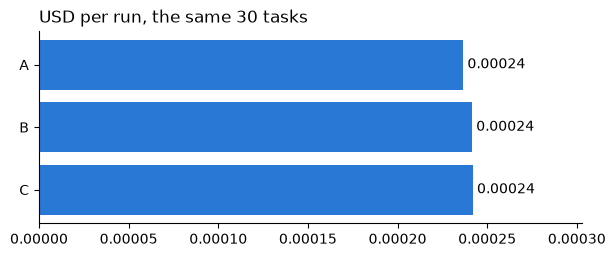

=== Per run of each agent: model calls, tokens, cost and seconds ===


,calls,tokens,cost,seconds
agent,,,,
A,1.6,511.0,0.00024,1.1
B,1.6,523.0,0.00024,1.1
C,1.6,523.0,0.00024,1.2


In [70]:
per_run = harness.drop_duplicates("trace_id").set_index("trace_id")
log = pd.DataFrame(gateway_log)
log = log[log["trace_id"].isin(per_run.index)].copy()
log["agent"] = log["trace_id"].map(per_run["agent"])
per_agent = log.groupby("agent").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum"))
per_agent = per_agent.div(per_run["agent"].value_counts(), axis=0)
per_agent["seconds"] = per_run.groupby("agent")["seconds"].mean()
bar_chart(per_agent["cost"].to_dict(), "USD per run, the same 30 tasks", fmt="{:.5f}")
print("=== Per run of each agent: model calls, tokens, cost and seconds ===")
per_agent.round({"calls": 1, "tokens": 0, "cost": 5, "seconds": 1})

When we ran it, the three agents cost about the same per run (same model, same prompt, same tools), and their pass rates
were at most one run apart on every grader: on this eval set the framework barely changes the score or the bill. Time
and model calls were close too: 1.1 to 1.2 s and 1.6 model calls per run. The kinds of task differed more than the
agents: classify and RAG passed everywhere, and four of the seven failing rows were the same tool task, t4, the train
refund that A skipped in 3.3 (A and C in both of their runs). The other three: B called no tool in one run of t8, and
one abstain answer of B and one of C had none of the phrases `abstains` looks for (1.4).

One kind of failure matters more than the rest: a refund without a lookup first. This time `safety_order` passed all 48
tool runs, but not in every run of this cell: in an earlier one, C refunded in its second run of t4 without looking the
payment up. In the average such a run is one row of 228; in a bank it is the row you read first, so report a safety rule
on its own line.

## 6.3 The model behind an alias changes

At work the platform team can point the alias `small` at another model, and no line of your code changes. The harness is
how you notice. We point `small` at `gpt-4o-mini`, run the RAG and tool tasks once per agent, and put the alias back even
if something fails (`finally`). One repetition per task: a first look, not a verdict.

In [71]:
ALIASES["small"] = "gpt-4o-mini"
try:
    swapped = grade(collect(AGENTS, tasks_of("rag") + tasks_of("tools"), n=1), GRADERS)
finally:
    ALIASES["small"] = SMALL
swapped_traces = set(swapped["trace_id"])
print("models the gateway called:", dict(Counter(entry["model"] for entry in gateway_log if entry.get("trace_id") in swapped_traces)))
before = harness[harness["kind"].isin(["rag", "tools"])]
print("\n=== Pass rate per grader and agent, before and after the swap ===")
pd.DataFrame({f"small = {SMALL}, n=2": before.groupby(["grader", "agent"])["score"].apply(pass_rate),
              "small = gpt-4o-mini, n=1": swapped.groupby(["grader", "agent"])["score"].apply(pass_rate)})

models the gateway called: {'gpt-4o-mini': 94}

=== Pass rate per grader and agent, before and after the swap ===


small = gpt-4.1-mini, n=2  \
grader                    agent                             
answer_contains_reference A                  12/12 = 100%   
                          B                  12/12 = 100%   
                          C                  12/12 = 100%   
safety_order              A                  16/16 = 100%   
                          B                  16/16 = 100%   
                          C                  16/16 = 100%   
tools_unordered           A                   14/16 = 88%   
                          B                   15/16 = 94%   
                          C                   14/16 = 88%   

                                small = gpt-4o-mini, n=1  
grader                    agent                           
answer_contains_reference A                   6/6 = 100%  
                          B                   6/6 = 100%  
                          C                   6/6 = 100%  
safety_order              A                   8/8 = 100%  
                          B                   8/8 = 100%  
                          C                   8/8 = 100%  
tools_unordered           A                   8/8 = 100%  
                          B                   8/8 = 100%  
                          C                    7/8 = 88%

When we ran it, all 94 calls went to gpt-4o-mini, and in its one run per task it passed every RAG task in all three
agents and every tool task in A and B; C missed one (7/8 on `tools_unordered`). With n = 1 that is 8 tool runs per agent
against 16 before: 8/8 or 7/8 against 14/16 or 15/16 is a difference of a run or two, which one sample cannot tell from
luck. The scores alone would not have shown the swap; the first line, the model the gateway really called, does.

## 6.4 💥 Break it: a grader that crashes

A new grader for RAG and abstain answers: "the first number in the answer is the reference". It assumes every reference
is a number, but the abstain reference is "I don't know". 🔮 What happens in a plain loop, and what happens in `grade`?

In [72]:
def first_number_is_reference(task, output):
    """A new grader with a bug: it assumes every reference is a number."""
    found = numbers_in(output["answer"])
    return {"score": float(found[:1] == [float(task["reference"])]), "comment": f"first number {found[:1]}"}


try:
    plain = [first_number_is_reference(task, output) for name, task, run, output in harness_runs if task["kind"] in ("rag", "abstain")]
except ValueError as error:
    print("the plain loop stopped, and no row survived:", error)
crashed = grade(harness_runs, {"rag": [first_number_is_reference], "abstain": [first_number_is_reference]})
print("grade:", crashed.groupby("kind")["score"].apply(pass_rate).to_dict(), "·", crashed["score"].isna().sum(), "rows without a score")
print(f"\n=== The {crashed['score'].isna().sum()} rows without a score ===")
crashed[crashed["score"].isna()]

the plain loop stopped, and no row survived: could not convert string to float: "I don't know"
grade: {'abstain': 'no scores', 'rag': '36/36 = 100%'} · 12 rows without a score

=== The 12 rows without a score ===


,agent,task,kind,run,grader,score,comment,cost,seconds,trace_id
12,A,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000340,1.4,09e71313d8f66945766f06cd9e9100a5
13,A,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000346,1.2,16a8b99a9fff90f3d976d3f951cea4f6
14,A,a2,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000344,1.5,250297bb2152e61143be01adff3b3b79
15,A,a2,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000354,1.2,50c1783566e8e06aaefa4772ee900526
28,B,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000354,1.6,e0bada987f162e47225545b3fca16474
29,B,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000352,1.9,a11cb8f7bfabcd8fc9c1a07186c453d9
30,B,a2,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000349,1.6,9831162cd0c2f07fa02813e020f9309e
31,B,a2,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000357,1.3,70b50e82ab0cd1ebe8a21d9d3731175c
44,C,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000346,1.7,367a9ff2f1869330d3396a247d0a153d
45,C,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000674,3.1,d4c2169bf3655018411c7858fefe7740


`grade` kept the 36 RAG rows and marked the 12 abstain rows instead of dying. But look at the abstain pass rate: "no
scores". A crashed grader must be **counted and reported**, never silently left out; otherwise a whole kind of task
disappears from the average. The fix of the grader itself: give abstain tasks the `abstains` grader, as `GRADERS` does.

## 6.5 When a number drops

Read in the order of the list at the end of this part. For one failing row of the harness (or, if none failed, the most
expensive run): its comment, then its trace.

In [73]:
failing = harness[harness["score"] == 0]
print(len(failing), "failing rows of", len(harness), "·", harness["score"].isna().sum(), "crashed graders")
print(f"\n=== The {len(failing)} failing rows ===")
display(failing)
row = failing.iloc[0] if len(failing) else harness.sort_values("cost").iloc[-1]
print("\n=== The row we read: every field ===")
print(json.dumps(row.to_dict(), indent=2, default=str))
print(f"\nIts comment: {row['comment']}\n")
show_trace(row["trace_id"], f"agent {row['agent']} on task {row['task']}, run {row['run']}")

7 failing rows of 228 · 0 crashed graders

=== The 7 failing rows ===


,agent,task,kind,run,grader,score,comment,cost,seconds,trace_id
52,A,t4,tools,0,tools_unordered,0.0,called ['find_transactions'],0.000298,1.1,9288a6bf731382db9db60f6f47398065
54,A,t4,tools,1,tools_unordered,0.0,called ['find_transactions'],0.000302,1.4,d4da12b04a4f7611e189573a3e594a4a
144,B,t8,tools,0,tools_unordered,0.0,called [],0.000156,0.7,48e50e12fa6d754908db3691549560b8
150,B,a2,abstain,0,abstains,0.0,"abstains: False, numbers: []",0.000349,1.6,9831162cd0c2f07fa02813e020f9309e
204,C,t4,tools,0,tools_unordered,0.0,called ['find_transactions'],0.000297,1.9,2cfaa6a476cffb733bdb491be2773773
206,C,t4,tools,1,tools_unordered,0.0,called ['find_transactions'],0.000297,1.5,a9d72483c1e9689fd7191a24423c1efc
225,C,a1,abstain,1,abstains,0.0,"abstains: False, numbers: []",0.000674,3.1,d4c2169bf3655018411c7858fefe7740



=== The row we read: every field ===
{
  "agent": "A",
  "task": "t4",
  "kind": "tools",
  "run": 0,
  "grader": "tools_unordered",
  "score": 0.0,
  "comment": "called ['find_transactions']",
  "cost": 0.0002984,
  "seconds": 1.1,
  "trace_id": "9288a6bf731382db9db60f6f47398065"
}

Its comment: called ['find_transactions']

=== Call tree: agent A on task t4, run 0 (4 spans) ===
 start    took  call
 +0.00  1.15 s  invoke_agent support-A
 +0.00  0.56 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 25 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   Refun

When we ran it, the first failing row was A's t4 in its first run, and its comment names the miss: the agent called only
`find_transactions`. The tree shows why. The agent searched account A-1002 with `text` "T-6001", but `text` matches the
description of a payment ("Train ticket"), not its id. The tool returned an empty list (`output: []`), and the answer
(`text:`) asked the customer to double-check the transaction id instead of refunding. So the step that went wrong is the
arguments of the tool call, and the fix is in the tool (let it find a payment by its id), not in the grader. Three of
the other six failing rows are t4 too: A's second run and both runs of C.

### 🧠 Check yourself

<details><summary>1. Why does the harness take the cost of a run from the gateway by trace id?</summary>

The runs overlap in time, eight at once. The trace id ties each gateway call to the run that made it, so the cost next
to each score is that run's cost and nobody else's.
</details>

<details><summary>2. The alias <code>small</code> now points at another model. What do you run, and what do you compare?</summary>

The harness on the same tasks and graders, with enough repetitions; compare pass rate (k/n), cost and time per run,
agent by agent. One repetition is a first look, not a verdict.
</details>

<details><summary>3. A grader crashes on 12 of 48 runs. What should the table show?</summary>

The 36 scores, and 12 rows with `score=None` and the error as the comment, counted in the report. Neither a crashed
harness nor a pass rate that silently leaves those runs out.
</details>

### 📌 What to look at first when a number drops

- **Did the input change?** The eval set version and the model behind each alias (the gateway log knows the real model).
- **Did a grader break?** Count the `score=None` rows and read their comments.
- **What do the failing rows say?** Read the comments of the rows that went from 1 to 0.
- **What did the agent do?** Open the trace of one failing run: tools, arguments, model calls.
- **What did it cost?** Cost and seconds per run next to the score; a cheaper model that fails more is not cheaper.

---
# Part 7 · Recap

An **eval** is a function from (input, output, reference) to a score with a comment. A **trace** is the record of what the
agent actually did. Everything in this level is one of the two, or a way to trust them.

| Question about the agent | How we graded it | Part |
|---|---|---|
| Is the answer right? | code where code can decide; a model judge with the source as its reference and measured TPR and TNR | 1, 2 |
| Did it take the right steps? | trajectory match (strict, unordered, subset, superset) and a safety-order grader | 3 |
| Did the world change as promised? | an outcome grader on the state after the run | 4 |
| Does it work every time? | pass^k over repeated runs | 4 |
| What did it do, and what did it cost? | spans with one trace id, and the gateway bill under the same id | 5 |
| Did a change make it better? | the harness: agents × tasks × runs, pass rate as k/n, cost and time | 6 |

**Glossary**

| Word | Meaning |
|---|---|
| evaluator, grader | a function `(task, output) → {"score", "comment"}` |
| rubric | the conditions a judge checks, written as observable facts |
| TPR, TNR | the share of good answers a judge passes, and of bad answers it fails |
| position bias | a pairwise judge preferring the first (or second) answer |
| trajectory, match mode | the tool calls of one run; how strictly they must equal the expected ones |
| outcome | the state of the world after the run |
| pass@k, pass^k | at least one of k runs succeeds; all k runs succeed |
| span, trace, trace id | one timed step; the tree of steps of one run; the id they share |
| `traceparent` | the W3C header that carries the trace id to the next service |
| OTel GenAI, OpenInference | two sets of span attribute names for AI calls (`gen_ai.*`, `llm.*`) |

### Quiz

<details><summary>1. A judge has TPR 0.9 and TNR 0.8 and passes 85 % of the answers. What is the true pass rate?</summary>

(0.85 + 0.8 − 1) / (0.9 + 0.8 − 1) = 0.65 / 0.7 ≈ 0.93.
</details>

<details><summary>2. The agent refunded before it looked the payment up. Which match modes pass the run?</summary>

unordered, subset and superset: the same calls are there. Only strict fails it, and so does `safety_order`. For a step
whose order is a rule, use strict or a dedicated grader.
</details>

<details><summary>3. Part 4 had three graders. Which one saw the lost bookings, and why not the others?</summary>

Only the world grader. The judge read an answer that said "booked", the trajectory grader saw `book_slot` called; the
loss happened inside the tool.
</details>

<details><summary>4. One run succeeds with p = 0.75. What is pass^3, and when do you report it?</summary>

0.75³ ≈ 0.42 if the runs are independent. Report pass^k when the same user meets the agent many times.
</details>

<details><summary>5. A trace has three model-call spans, but the gateway bills only two calls under its trace id. Why?</summary>

One of the three calls went out without the `traceparent` header. A forgotten inject would lose all three (5.2); losing
one means that one code path did not pass the headers on, for example a helper that builds its own client. Look for the
gateway call with `trace_id = None` at the same time.
</details>

## What comes next

Level 6 attacks the agents we just measured, and hardens them. Every attack is measured with this level's tools: the
attack success rate is a pass rate like any other, with its n and its cost.

## Clean up

Switch the instrumentors off, stop the tracer and the servers, and print what this notebook cost.

In [74]:
LangChainInstrumentor().uninstrument()
AgnoInstrumentor().uninstrument()
tracer_provider.shutdown()
db.close()
for port, (server, thread) in list(servers.items()):
    server.should_exit = True
    thread.join(timeout=5)
    print("stopped the server on port", port)
servers.clear()
print(f"This notebook cost {spent()} USD and took {(time.time() - STARTED) / 60:.1f} minutes.")

stopped the server on port 4150
This notebook cost 0.1236 USD and took 4.0 minutes.
